# Two Roads to Failure? Explanation Drift in Deepfake Detectors
### under Unseen Generators and Image Degradation — CMPT 819 Term Project
*Washikur Rahman (ozj079) · Tahsina Moiukh (rnk048)*

**Research question.** When a deepfake detector fails on an *unseen generator* or on a *degraded image*, does it lose the same visual evidence in both cases?

| Objective | Where in this notebook |
|---|---|
| **O1** Build the detector: face-crop pipeline + fine-tuned CNN, accuracy on known generators | §2–§6, **Trial 1** (§7) |
| **O2** Measure both failures: unseen generator, degradation, and both at once | **Trial 2** (§8) |
| **O3** Explanation drift: Grad-CAM, face focus, Explanation Stability Score (ESS) vs. performance loss | **Trial 3** (§9) |
| **O4** Causality: face-only vs. background-only vs. random-region degradation | **Trial 4** (§10) |
| Deliverables: statistics, summary, demo, exports | §11–§14 |

**How to run**
1. Kernel: **Python (CMPT819 Deepfake)** (created by `setup_env.sh` / `setup_env.bat`).
2. Folder layout: this notebook next to `Dataset/` with sub-folders `wiki/` (real), `text2img/` (SD v1.5), `inpainting/` (SD Inpainting), `insight/` (InsightFace).
3. **First run with `SMOKE_TEST = True`** (§1). It goes through every cell on ~400 images/class in a few minutes and writes to `work_smoke/`. Then set it to `False` for the real run (writes to `work/`).
4. Every expensive step is cached (detections, crops, checkpoints, predictions, Grad-CAMs). If the kernel dies, re-run from the top and it resumes.

Rough full-run cost on one modern GPU: preprocessing 20–40 min, 14 models × ≤8 epochs ≈ 3–5 h, evaluation + Grad-CAM ≈ 1 h.

## 1 · Configuration
All knobs live here. Two settings matter for validity and are **on by default** (see §2 for why):
- `MATCH_PAIR_RESOLUTION` – each fake crop is brought down to the native resolution of its paired real crop, so the detector cannot win by "real = low-res/blurry, fake = sharp 512 px".
- `EQUALIZE_JPEG_Q` – every crop passes through one identical JPEG round, so "has JPEG traces vs. lossless" is not a free label.

In [22]:
import os, sys, json, hashlib, platform, warnings
from pathlib import Path

SMOKE_TEST = False         # <- set True for a quick end-to-end check first

PROJECT   = Path.cwd()      # folder that holds this notebook and Dataset/
DATA_ROOT = PROJECT / "Dataset"
WORK      = PROJECT / ("work_smoke" if SMOKE_TEST else "work")
CROP_DIR, CKPT_DIR, PRED_DIR = WORK / "crops", WORK / "checkpoints", WORK / "preds"
CAM_DIR, RES_DIR, FIG_DIR    = WORK / "cams", WORK / "results", WORK / "figures"
for d in (CROP_DIR, CKPT_DIR, PRED_DIR, CAM_DIR, RES_DIR, FIG_DIR, PROJECT / "src"):
    d.mkdir(parents=True, exist_ok=True)
(PROJECT / "src" / "__init__.py").touch()
if str(PROJECT) not in sys.path:
    sys.path.insert(0, str(PROJECT))

# ---- data
REAL = "wiki"
GENERATORS = {"text2img": "SD v1.5", "inpainting": "SD Inpainting", "insight": "InsightFace"}
GENS = list(GENERATORS)
CLASSES = [REAL] + GENS
N_PER_CLASS = 25_000                                    # proposal: 17.5k / 5k / 2.5k per class
SPLIT_FRACS = {"train": 0.70, "test": 0.20, "val": 0.10}
SEED = 819

# ---- preprocessing
DETECT_SIZE, MIN_FACE_PROB = 512, 0.90                  # MTCNN runs on 512x512 letterboxed copies
CROP_SIZE, CROP_MARGIN = 320, 1.7                       # square crop = 1.7 x face box (keeps some background)
MATCH_PAIR_RESOLUTION = True
EQUALIZE_JPEG_Q = 95                                    # None to disable

# ---- models / training
ARCHS = ["resnet18", "xception"]
TRAIN_CFG = dict(epochs=2, lr=1e-4, weight_decay=1e-4, patience=2, amp=True)
BATCH_SIZE = {"resnet18": 16, "xception": 16}          # RTX A2000 12 GB: keep every batch size <= 16
RUN_HP_SWEEP, LR_GRID, HP_SWEEP_EPOCHS = False, [3e-5, 1e-4, 3e-4], 3
NUM_WORKERS = min(4, os.cpu_count() or 2)
EVAL_BATCH = 16                                         # inference / Grad-CAM / MTCNN batches

# ---- analysis
N_BOOT, N_BOOT_GRID = 1000, 300                         # bootstrap resamples (headline CIs / big test grid)
CAM_N_PER_CLASS, CAM_RES = 300, 32                      # Grad-CAM sample size and stored heat-map resolution
MEDIUM = {"blur": "blur@2", "resize": "resize@1", "noise": "noise@2", "jpeg": "jpeg@3", "social": "social@2"}
T4_CONDS = ["blur@2", "jpeg@3"]                         # Gaussian σ=2 and JPEG Q=50 for the region test
T4_REGIONS = ["full", "face", "background", "random"]
RUN_REMEDY, REMEDY_AUG_P = False, 0.5                   # optional §12: training with degraded images

if SMOKE_TEST:
    N_PER_CLASS = 400
    TRAIN_CFG.update(epochs=1, patience=1)
    RUN_HP_SWEEP, HP_SWEEP_EPOCHS, LR_GRID = True, 1, [1e-4, 3e-4]
    N_BOOT, N_BOOT_GRID, CAM_N_PER_CLASS = 100, 50, 40

print(f"Project: {PROJECT}\nData:    {DATA_ROOT}  (exists: {DATA_ROOT.exists()})\nWork:    {WORK}\nSMOKE_TEST = {SMOKE_TEST}")

Project: /tmp/ozj079/CMPT819Project
Data:    /tmp/ozj079/CMPT819Project/Dataset  (exists: True)
Work:    /tmp/ozj079/CMPT819Project/work
SMOKE_TEST = False


In [2]:
import random, time, math
import numpy as np, pandas as pd, matplotlib.pyplot as plt, cv2
import torch
from torch.utils.data import DataLoader
from tqdm.auto import tqdm
from PIL import Image
from IPython.display import display
from scipy import stats

warnings.filterwarnings("ignore", category=UserWarning)
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
assert torch.cuda.is_available(), "No CUDA GPU visible to PyTorch – this notebook is set up to run on the GPU."
DEVICE = MTCNN_DEVICE = torch.device("cuda")
torch.backends.cudnn.benchmark = True
print(f"Python {platform.python_version()} | torch {torch.__version__} | device {DEVICE} ({torch.cuda.get_device_name(0)}, "
      f"{torch.cuda.get_device_properties(0).total_memory / 2**30:.1f} GB)")

pd.set_option("display.precision", 4); pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "axes.spines.top": False, "axes.spines.right": False})
def savefig(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight")

def sample_per_class(df, n, seed=SEED):
    return pd.concat([d.sample(min(len(d), n), random_state=seed) for _, d in df.groupby("cls", sort=False)],
                     ignore_index=True)

Python 3.14.4 | torch 2.14.1+cu126 | device cuda (NVIDIA RTX A2000 12GB, 11.6 GB)


## 2 · Dataset indexing & exploratory analysis
DeepFakeFace (DFF) pairs every real IMDB-WIKI photo with three fakes that share its file name. We index all four folders, check how many images are **paired** across all four, look at file formats and resolutions (classic shortcut sources), and show paired examples (Fig. 1 of the proposal).

In [3]:
IMG_EXT = {".jpg", ".jpeg", ".png", ".webp", ".bmp"}

def index_class(cls):
    root = DATA_ROOT / cls
    assert root.exists(), f"Missing folder: {root}"
    rows = []
    for p in root.rglob("*"):
        if p.suffix.lower() in IMG_EXT and not p.name.startswith("."):
            parent = p.parent.name
            # key = '<bucket>/<stem>' (e.g. '00/12345_1980-01-01_2010'); it is the same across the 4 classes
            key = p.stem if (p.parent == root or parent.lower() in CLASSES) else f"{parent}/{p.stem}"
            rows.append((cls, key, str(p), p.suffix.lower()))
    return pd.DataFrame(rows, columns=["cls", "key", "path", "ext"])

index_csv = WORK / "index.csv"
if index_csv.exists():
    full = pd.read_csv(index_csv, dtype={"key": str})
else:
    full = pd.concat([index_class(c) for c in tqdm(CLASSES, desc="indexing")], ignore_index=True)
    full = full.drop_duplicates(["cls", "key"]).reset_index(drop=True)
    full.to_csv(index_csv, index=False)

key_sets = {c: set(full.loc[full.cls == c, "key"]) for c in CLASSES}
PAIRED = set.intersection(*key_sets.values())
print("Images per class:"); display(full.cls.value_counts().reindex(CLASSES).to_frame("n"))
print("File formats per class:"); display(pd.crosstab(full.cls, full.ext).reindex(CLASSES))
print(f"Keys present in all 4 classes (paired): {len(PAIRED):,}")
for g in GENS:
    print(f"  {REAL} ∩ {g}: {len(key_sets[REAL] & key_sets[g]):,}")

Images per class:


,n
cls,
wiki,30000
text2img,30000
inpainting,30000
insight,30000


File formats per class:


ext,.jpg
cls,
wiki,30000
text2img,30000
inpainting,30000
insight,30000


Keys present in all 4 classes (paired): 30,000
  wiki ∩ text2img: 30,000
  wiki ∩ inpainting: 30,000
  wiki ∩ insight: 30,000


reading headers:   0%|          | 0/6000 [00:00<?, ?it/s]

,count,mean,std,min,25%,50%,75%,max
cls,,,,,,,,
wiki,1500.0,389.6147,80.8663,122.0,331.0,440.0,440.0,600.0
text2img,1500.0,512.0000,0.0000,512.0,512.0,512.0,512.0,512.0
inpainting,1500.0,512.0000,0.0000,512.0,512.0,512.0,512.0,512.0
insight,1500.0,512.0000,0.0000,512.0,512.0,512.0,512.0,512.0


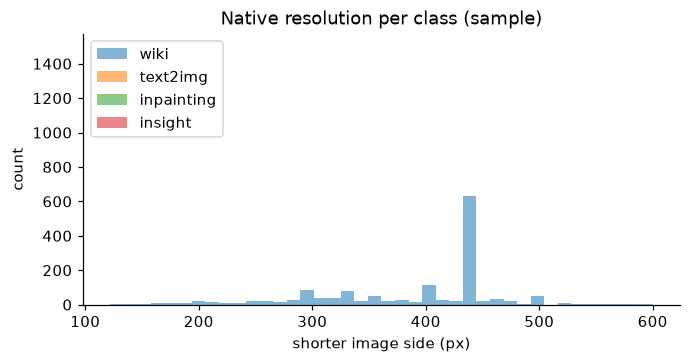

If the classes differ in resolution or format, a CNN can separate them without looking at any fake evidence.
MATCH_PAIR_RESOLUTION and EQUALIZE_JPEG_Q (§1) remove these two shortcuts at preprocessing time.


In [4]:
def img_size(p):
    try:
        with Image.open(p) as im:
            return im.size
    except Exception:
        return (np.nan, np.nan)

eda = sample_per_class(full, 1500)
eda[["w", "h"]] = [img_size(p) for p in tqdm(eda.path, desc="reading headers")]
eda["min_side"] = eda[["w", "h"]].min(axis=1)
display(eda.groupby("cls")["min_side"].describe().reindex(CLASSES))

fig, ax = plt.subplots(figsize=(7, 3.2))
for c in CLASSES:
    ax.hist(eda.loc[eda.cls == c, "min_side"].dropna(), bins=40, alpha=.55, label=c)
ax.set(xlabel="shorter image side (px)", ylabel="count", title="Native resolution per class (sample)")
ax.legend(); savefig(fig, "eda_resolution"); plt.show()
print("If the classes differ in resolution or format, a CNN can separate them without looking at any fake evidence.\n"
      "MATCH_PAIR_RESOLUTION and EQUALIZE_JPEG_Q (§1) remove these two shortcuts at preprocessing time.")

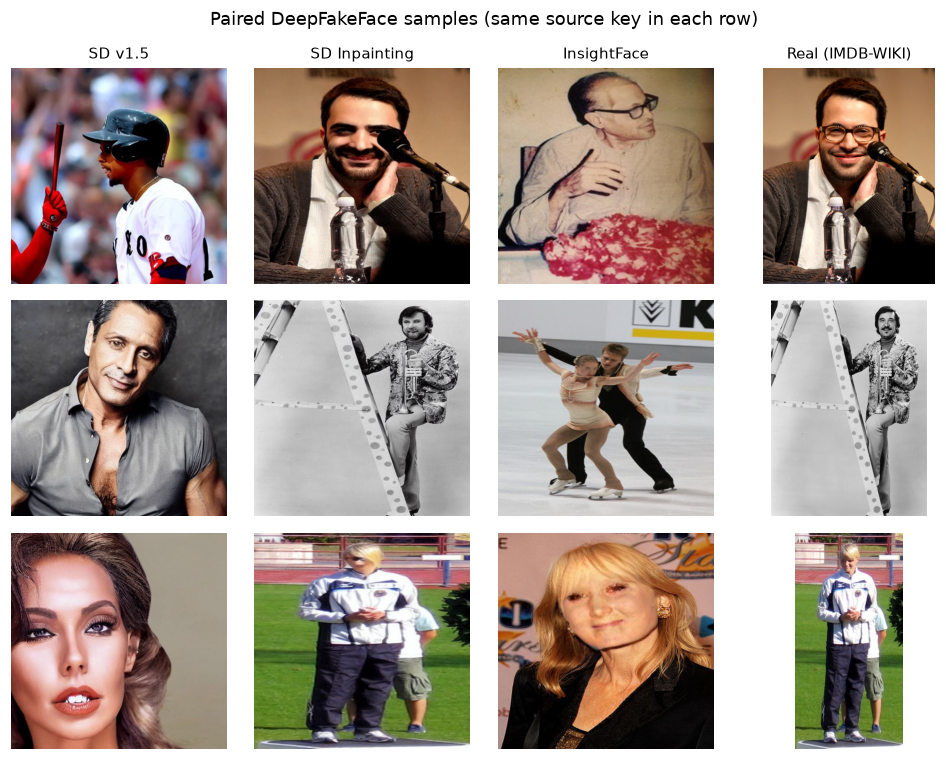

In [5]:
show_keys = random.Random(SEED).sample(sorted(PAIRED), 3) if len(PAIRED) >= 3 else []
if show_keys:
    fig, axes = plt.subplots(3, 4, figsize=(9, 7))
    order = GENS + [REAL]
    names = {**GENERATORS, REAL: "Real (IMDB-WIKI)"}
    for r, k in enumerate(show_keys):
        for c, cls in enumerate(order):
            p = full[(full.cls == cls) & (full.key == k)].path.iloc[0]
            axes[r, c].imshow(Image.open(p).convert("RGB")); axes[r, c].axis("off")
            if r == 0: axes[r, c].set_title(names[cls], fontsize=10)
    fig.suptitle("Paired DeepFakeFace samples (same source key in each row)"); fig.tight_layout()
    savefig(fig, "fig1_dff_samples"); plt.show()

## 3 · Sample selection & identity-disjoint split (70 / 20 / 10)
We draw `N_PER_CLASS` **paired** keys so that every real image appears with its three fakes. The split is done by **person**
(the IMDB-WIKI id at the start of the file name), so no identity – and no real/fake pair – crosses train/test/val. A hash of the person id makes the split deterministic.

In [6]:
rng = np.random.default_rng(SEED)
paired_sorted = sorted(PAIRED)
if len(paired_sorted) >= N_PER_CLASS:
    chosen = set(rng.choice(paired_sorted, N_PER_CLASS, replace=False))
    sel = full[full.key.isin(chosen)].copy()
else:
    print(f"Only {len(paired_sorted):,} paired keys – topping up with unpaired images per class.")
    parts = []
    for c in CLASSES:
        d = full[full.cls == c]
        p_, rest = d[d.key.isin(PAIRED)], d[~d.key.isin(PAIRED)]
        parts += [p_, rest.sample(min(max(0, N_PER_CLASS - len(p_)), len(rest)), random_state=SEED)]
    sel = pd.concat(parts)

sel["person"] = sel.key.str.split("/").str[-1].str.split("_").str[0]
def split_of(group):
    u = int(hashlib.md5(f"{SEED}-{group}".encode()).hexdigest()[:8], 16) / 0xFFFFFFFF
    return "train" if u < SPLIT_FRACS["train"] else ("test" if u < SPLIT_FRACS["train"] + SPLIT_FRACS["test"] else "val")
sel["split"] = sel.person.map(split_of)
sel["label"] = (sel.cls != REAL).astype(int)
sel["uid"] = sel.cls + "/" + sel.key
sel["paired"] = sel.key.isin(PAIRED)
sel = sel.reset_index(drop=True)

display(pd.crosstab(sel.cls, sel.split).reindex(index=CLASSES, columns=["train", "test", "val"]))
leak = {(a, b): len(set(sel.person[sel.split == a]) & set(sel.person[sel.split == b]))
        for a, b in [("train", "test"), ("train", "val"), ("test", "val")]}
print("Shared persons between splits (must be 0):", leak)
sel.to_csv(WORK / "selection.csv", index=False)

split,train,test,val
cls,,,
wiki,17546,4984,2470
text2img,17546,4984,2470
inpainting,17546,4984,2470
insight,17546,4984,2470


Shared persons between splits (must be 0): {('train', 'test'): 0, ('train', 'val'): 0, ('test', 'val'): 0}


## 4 · Preprocessing: MTCNN face crops and face ROI masks
1. **Detect** – MTCNN on a 512×512 letterboxed copy of each image (batched on GPU); keep the largest face with p ≥ 0.90 and its 5 landmarks.
2. **Crop** – square crop of 1.7 × the face box, shifted (never padded) to stay inside the image, resized to 320 px. Fakes are first brought down to the native resolution of their paired real crop; every crop goes through one JPEG Q=95 round.
3. **ROI mask** – a filled ellipse placed from the box and landmark centroid, rotated by the eye line. This is the "face region" for Grad-CAM energy (Trial 3) and region degradation (Trial 4).

The module below is written to `src/faces.py` (code that runs inside DataLoader workers must live in a file so it works on Windows/macOS).

In [7]:
%%writefile src/faces.py
"""Face detection (MTCNN) helpers, face cropping, and the landmark-aligned face ROI mask."""
import math
from pathlib import Path

import cv2
import numpy as np

try:
    import torch
    from torch.utils.data import Dataset
except ImportError:          # lets the numpy parts be used/tested without torch
    Dataset = object


def read_rgb(path):
    img = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if img is None:
        raise IOError(f"Cannot read {path}")
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)


def letterbox(img, size):
    """Resize keeping aspect ratio and pad to size x size, so images of any shape can be batched for MTCNN."""
    h, w = img.shape[:2]
    scale = size / max(h, w)
    nh, nw = max(1, round(h * scale)), max(1, round(w * scale))
    resized = cv2.resize(img, (nw, nh), interpolation=cv2.INTER_AREA if scale < 1 else cv2.INTER_LINEAR)
    canvas = np.zeros((size, size, 3), np.uint8)
    py, px = (size - nh) // 2, (size - nw) // 2
    canvas[py:py + nh, px:px + nw] = resized
    return canvas, scale, px, py


class DetectDataset(Dataset):
    def __init__(self, paths, size=512):
        self.paths, self.size = list(paths), size

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        try:
            img = read_rgb(self.paths[i])
            h, w = img.shape[:2]
            canvas, scale, px, py = letterbox(img, self.size)
            return canvas, (i, scale, px, py, w, h, 1)
        except Exception:
            return np.zeros((self.size, self.size, 3), np.uint8), (i, 1.0, 0, 0, 0, 0, 0)


def detect_collate(batch):
    imgs = np.stack([b[0] for b in batch])
    meta = np.array([b[1] for b in batch], dtype=np.float64)
    return imgs, meta


def mtcnn_detect(mtcnn, imgs):
    """Batched MTCNN on uint8 images (B, H, W, 3). Returns one (boxes, probs, points) tuple per image,
    (None, None, None) when nothing is found. Calls facenet-pytorch's detect_face directly, because
    MTCNN.detect() packs batch results into ragged arrays that recent NumPy versions reject."""
    import torch
    try:
        from facenet_pytorch.models.utils.detect_face import detect_face
        with torch.no_grad():
            batch_boxes, batch_points = detect_face(imgs, mtcnn.min_face_size, mtcnn.pnet, mtcnn.rnet, mtcnn.onet,
                                                    mtcnn.thresholds, mtcnn.factor, mtcnn.device)
        out = []
        for box, pts in zip(batch_boxes, batch_points):
            box = np.asarray(box, dtype=np.float64).reshape(-1, 5) if len(box) else np.zeros((0, 5))
            out.append((None, None, None) if len(box) == 0 else
                       (box[:, :4], box[:, 4], np.asarray(pts, dtype=np.float64).reshape(-1, 5, 2)))
        return out
    except ImportError:
        boxes, probs, points = mtcnn.detect(imgs, landmarks=True)
        return list(zip(boxes, probs, points))


def pick_face(boxes, probs, points, min_prob=0.9):
    """Return (box[4], landmarks[5,2], prob) of the largest confident face, or None."""
    if boxes is None or probs is None or len(boxes) == 0:
        return None
    boxes = np.asarray(boxes, dtype=np.float64).reshape(-1, 4)
    probs = np.asarray(probs, dtype=np.float64).reshape(-1)
    points = np.asarray(points, dtype=np.float64).reshape(-1, 5, 2)
    ok = probs >= min_prob
    if not ok.any():
        return None
    area = (boxes[:, 2] - boxes[:, 0]) * (boxes[:, 3] - boxes[:, 1])
    area[~ok] = -1
    j = int(np.argmax(area))
    return boxes[j], points[j], float(probs[j])


def square_crop_params(box, W, H, margin):
    """Square crop centred on the face box, `margin` x the box size, shifted (not padded) to stay inside."""
    if box is None or not np.all(np.isfinite(box)):
        side = min(W, H)
        return (W - side) / 2, (H - side) / 2, float(side)
    x0, y0, x1, y1 = box
    side = min(margin * max(x1 - x0, y1 - y0), W, H)
    cx, cy = (x0 + x1) / 2, (y0 + y1) / 2
    cx0 = float(np.clip(cx - side / 2, 0, W - side))
    cy0 = float(np.clip(cy - side / 2, 0, H - side))
    return cx0, cy0, float(side)


def make_crop(img, cx0, cy0, cside, target_side=None, crop_size=320, jpeg_q=95):
    """Cut the square crop, optionally downsample to `target_side` (paired real's native resolution),
    resize to crop_size, and pass through one JPEG(q) round so every class carries the same compression."""
    xa, ya = int(round(cx0)), int(round(cy0))
    sa = max(1, int(round(cside)))
    crop = img[ya:ya + sa, xa:xa + sa]
    t = int(round(target_side)) if target_side is not None and np.isfinite(target_side) else crop.shape[0]
    if 0 < t < crop.shape[0]:
        crop = cv2.resize(crop, (t, t), interpolation=cv2.INTER_AREA)
    interp = cv2.INTER_AREA if crop.shape[0] > crop_size else cv2.INTER_CUBIC
    crop = cv2.resize(crop, (crop_size, crop_size), interpolation=interp)
    if jpeg_q:
        ok, buf = cv2.imencode(".jpg", cv2.cvtColor(crop, cv2.COLOR_RGB2BGR), [cv2.IMWRITE_JPEG_QUALITY, int(jpeg_q)])
        crop = cv2.cvtColor(cv2.imdecode(buf, cv2.IMREAD_COLOR), cv2.COLOR_BGR2RGB)
    return crop


def crop_geometry(box, landmarks, cx0, cy0, cside):
    """Face box and 5 landmarks expressed in normalised crop coordinates (0..1)."""
    g = {"fx0": np.nan, "fy0": np.nan, "fx1": np.nan, "fy1": np.nan}
    g.update({f"l{i}{a}": np.nan for i in range(5) for a in "xy"})
    if box is not None:
        g.update(fx0=(box[0] - cx0) / cside, fy0=(box[1] - cy0) / cside,
                 fx1=(box[2] - cx0) / cside, fy1=(box[3] - cy0) / cside)
    if landmarks is not None:
        for i in range(5):
            g[f"l{i}x"] = (landmarks[i][0] - cx0) / cside
            g[f"l{i}y"] = (landmarks[i][1] - cy0) / cside
    return g


class CropDataset(Dataset):
    """Runs make_crop for every record in DataLoader workers and saves the crop as PNG (skips existing files)."""

    def __init__(self, records, crop_size=320, jpeg_q=95):
        self.records, self.crop_size, self.jpeg_q = list(records), crop_size, jpeg_q

    def __len__(self):
        return len(self.records)

    def __getitem__(self, i):
        r = self.records[i]
        out = Path(r["crop_path"])
        if out.exists():
            return i, 1
        try:
            crop = make_crop(read_rgb(r["path"]), r["cx0"], r["cy0"], r["cside"], r.get("target_side"),
                             self.crop_size, self.jpeg_q)
            out.parent.mkdir(parents=True, exist_ok=True)
            cv2.imwrite(str(out), cv2.cvtColor(crop, cv2.COLOR_RGB2BGR))
            return i, 1
        except Exception:
            return i, 0


# ---------------------------------------------------------------- face ROI mask
def face_mask(meta, size, margin=1.7):
    """Filled ellipse over the face, in crop coordinates (0..size).
    Centre from the box and the 5 landmarks, size from the MTCNN box, rotation from the eye line.
    `meta` holds normalised crop-space values: fx0, fy0, fx1, fy1, and l0x..l4y (left eye, right eye, nose, mouth L, mouth R)."""
    m = np.zeros((size, size), np.float32)
    detected = bool(meta.get("detected", False)) and np.isfinite(meta.get("fx0", np.nan))
    if detected:
        x0, y0, x1, y1 = (meta[k] * size for k in ("fx0", "fy0", "fx1", "fy1"))
        lm = np.array([[meta[f"l{i}x"], meta[f"l{i}y"]] for i in range(5)], dtype=np.float64) * size
        bcx, bcy = (x0 + x1) / 2, (y0 + y1) / 2
        if np.all(np.isfinite(lm)):
            lcx, lcy = lm[:, 0].mean(), lm[:, 1].mean()
            cx, cy = 0.5 * (bcx + lcx), 0.5 * (bcy + lcy)
            angle = math.degrees(math.atan2(lm[1, 1] - lm[0, 1], lm[1, 0] - lm[0, 0]))
        else:
            cx, cy, angle = bcx, bcy, 0.0
        ax, ay = 0.5 * (x1 - x0), 0.55 * (y1 - y0)
    else:                                    # no detection: centred default ellipse of the expected size
        cx = cy = size / 2
        ax = size / (2 * margin)
        ay = 1.2 * ax
        angle = 0.0
    cv2.ellipse(m, (int(round(cx)), int(round(cy))), (max(1, int(round(ax))), max(1, int(round(ay)))),
                angle, 0, 360, 1.0, -1)
    return m

Overwriting src/faces.py


In [8]:
import importlib, src.faces as faces
importlib.reload(faces)

PRE_CFG = dict(DETECT_SIZE=DETECT_SIZE, MIN_FACE_PROB=MIN_FACE_PROB, CROP_SIZE=CROP_SIZE, CROP_MARGIN=CROP_MARGIN,
               MATCH_PAIR_RESOLUTION=MATCH_PAIR_RESOLUTION, EQUALIZE_JPEG_Q=EQUALIZE_JPEG_Q)
cfg_file = WORK / "preprocess_cfg.json"
if cfg_file.exists() and json.loads(cfg_file.read_text()) != PRE_CFG:
    print("!! Preprocessing settings changed since crops were cached – delete", CROP_DIR, "and", WORK / "detections.csv")
cfg_file.write_text(json.dumps(PRE_CFG, indent=1))

# ---- Step 1: detection (resumable, saved every 100 batches)
det_csv = WORK / "detections.csv"
det = pd.read_csv(det_csv) if det_csv.exists() else pd.DataFrame(columns=["uid"])
todo = sel[~sel.uid.isin(set(det.uid))].reset_index(drop=True)
print(f"Detection: {len(det):,} cached, {len(todo):,} to do")
if len(todo):
    from facenet_pytorch import MTCNN
    mtcnn = MTCNN(keep_all=True, device=MTCNN_DEVICE, post_process=False)
    loader = DataLoader(faces.DetectDataset(todo.path.tolist(), DETECT_SIZE), batch_size=EVAL_BATCH,
                        num_workers=NUM_WORKERS, collate_fn=faces.detect_collate)
    uids, recs = todo.uid.tolist(), []
    for bi, (imgs, meta_b) in enumerate(tqdm(loader, desc="MTCNN")):
        found = faces.mtcnn_detect(mtcnn, imgs)
        for b in range(len(imgs)):
            i, scale, px, py, W, H, ok = meta_b[b]
            rec = dict(uid=uids[int(i)], W=int(W), H=int(H), readable=int(ok), detected=0, prob=np.nan)
            face = faces.pick_face(*found[b], MIN_FACE_PROB) if ok else None
            if face is not None:
                box, lm, pr = face
                box = (box - np.array([px, py, px, py])) / scale
                lm = (lm - np.array([px, py])) / scale
                rec.update(detected=1, prob=pr, bx0=box[0], by0=box[1], bx1=box[2], by1=box[3],
                           **{f"lm{k}{a}": lm[k][j] for k in range(5) for j, a in enumerate("xy")})
            recs.append(rec)
        if (bi + 1) % 100 == 0:
            pd.concat([det, pd.DataFrame(recs)], ignore_index=True).to_csv(det_csv, index=False)
    det = pd.concat([det, pd.DataFrame(recs)], ignore_index=True)
    det.to_csv(det_csv, index=False)
    del mtcnn

Detection: 100,000 cached, 0 to do


In [9]:
# ---- Step 2: crop geometry, resolution matching, ROI geometry in crop coordinates
meta = sel.merge(det, on="uid", how="left")
meta = meta[meta.readable.fillna(0).astype(int) == 1].copy()
meta["detected"] = meta.detected.fillna(0).astype(int)

geo = []
for r in meta.itertuples(index=False):
    box = np.array([r.bx0, r.by0, r.bx1, r.by1]) if r.detected else None
    lm = np.array([[getattr(r, f"lm{k}x"), getattr(r, f"lm{k}y")] for k in range(5)]) if r.detected else None
    cx0, cy0, cside = faces.square_crop_params(box, r.W, r.H, CROP_MARGIN)
    geo.append(dict(cx0=cx0, cy0=cy0, cside=cside, **faces.crop_geometry(box, lm, cx0, cy0, cside)))
meta = pd.concat([meta.reset_index(drop=True), pd.DataFrame(geo)], axis=1)

if MATCH_PAIR_RESOLUTION:
    real_side = meta[meta.cls == REAL].set_index("key")["cside"]
    paired_side = meta.key.map(real_side)
    meta["target_side"] = np.where((meta.cls != REAL) & paired_side.notna(),
                                   np.minimum(meta.cside, paired_side.fillna(np.inf)), meta.cside)
else:
    meta["target_side"] = meta.cside
meta["crop_path"] = [str(CROP_DIR / c / (k.replace("/", "__") + ".png")) for c, k in zip(meta.cls, meta.key)]

# ---- Step 3: write the crops (parallel, skips files that already exist)
crop_loader = DataLoader(faces.CropDataset(meta.to_dict("records"), CROP_SIZE, EQUALIZE_JPEG_Q),
                         batch_size=64, num_workers=NUM_WORKERS)
ok = np.zeros(len(meta), bool)
for idx, flag in tqdm(crop_loader, desc="cropping"):
    ok[idx.numpy()] = flag.numpy().astype(bool)
print(f"Crops OK: {ok.sum():,}/{len(meta):,}")
meta = meta[ok].reset_index(drop=True)
meta.to_csv(WORK / "meta.csv", index=False)

summary = meta.groupby("cls").agg(n=("uid", "size"), detected=("detected", "mean"), mean_prob=("prob", "mean"),
                                  native_crop_px=("cside", "median"), used_crop_px=("target_side", "median"))
display(summary.reindex(CLASSES))

cropping:   0%|          | 0/1563 [00:03<?, ?it/s]

Crops OK: 100,000/100,000


,n,detected,mean_prob,native_crop_px,used_crop_px
cls,,,,,
wiki,25000,0.9614,0.9971,209.7408,209.7408
text2img,25000,0.9432,0.9982,383.8596,190.6492
inpainting,25000,0.9276,0.9951,262.5448,196.9503
insight,25000,0.9282,0.9955,252.8605,156.8765


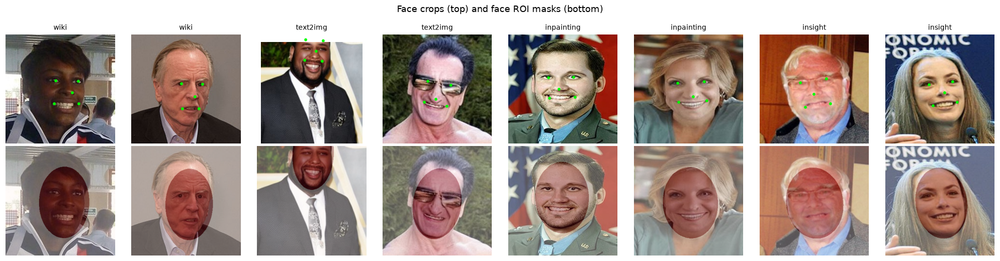

In [10]:
def overlay(img, cam, alpha=0.45):
    h = cv2.resize(np.asarray(cam, np.float32), img.shape[:2][::-1], interpolation=cv2.INTER_LINEAR)
    return np.clip((1 - alpha) * img / 255.0 + alpha * plt.get_cmap("jet")(np.clip(h, 0, 1))[..., :3], 0, 1)

ex = sample_per_class(meta[meta.detected == 1], 2)
fig, axes = plt.subplots(2, len(ex), figsize=(2.3 * len(ex), 4.8))
for j, r in enumerate(ex.to_dict("records")):
    img = faces.read_rgb(r["crop_path"])
    m = faces.face_mask(r, CROP_SIZE, CROP_MARGIN)
    axes[0, j].imshow(img); axes[0, j].set_title(r["cls"], fontsize=9)
    axes[0, j].scatter([r[f"l{i}x"] * CROP_SIZE for i in range(5)], [r[f"l{i}y"] * CROP_SIZE for i in range(5)], s=8, c="lime")
    axes[1, j].imshow(img); axes[1, j].imshow(m, alpha=.35, cmap="Reds")
    for a in axes[:, j]: a.axis("off")
axes[0, 0].set_ylabel("crop + landmarks"); fig.suptitle("Face crops (top) and face ROI masks (bottom)")
fig.tight_layout(); savefig(fig, "preprocessing_examples"); plt.show()

## 5 · Degradation module
Applied to the 320 px crop, before the resize to model input. Five families, each with increasing severity:

| family | levels | what it simulates |
|---|---|---|
| `blur` | Gaussian σ = 1, 2, 3 | defocus / motion softening |
| `resize` | down to ×0.5, ×0.25 then back up | thumbnails, low-res re-uploads |
| `noise` | Gaussian σ = 5, 10, 20 (of 255) | sensor noise / low light |
| `jpeg` | Q = 90, 70, 50, 30 | compression |
| `social` | (scale, Q, sharpen) = (.75, 85, .3), (.5, 75, .6), (.35, 60, 1.0) | a social-media upload: downscale → sharpen → JPEG → viewer upscales |

Randomness (noise, random regions) is seeded by image id + condition, so every model sees identical pixels. `apply_region_degradation` degrades the whole crop and keeps the degraded pixels only inside the face, the background, or a **random face-shaped region of equal area** (the control in Trial 4), with a 3-px soft edge.

In [11]:
%%writefile src/degrade.py
"""Degradation module: blur, down/up-scaling, noise, JPEG, social-media chain, and region-restricted degradation.

All functions take/return uint8 RGB numpy arrays (H, W, 3). Randomness is seeded from the image id and the
condition name, so every model sees exactly the same degraded pixels for a given image and condition.
"""
import hashlib
import cv2
import numpy as np


def stable_seed(*parts) -> int:
    return int(hashlib.md5("|".join(map(str, parts)).encode()).hexdigest()[:8], 16)


# ---------------------------------------------------------------- primitive degradations
def gaussian_blur(img, sigma, rng=None):
    return cv2.GaussianBlur(img, (0, 0), sigmaX=float(sigma), sigmaY=float(sigma),
                            borderType=cv2.BORDER_REFLECT_101)


def down_up(img, scale, rng=None):
    h, w = img.shape[:2]
    small = cv2.resize(img, (max(1, round(w * scale)), max(1, round(h * scale))), interpolation=cv2.INTER_AREA)
    return cv2.resize(small, (w, h), interpolation=cv2.INTER_CUBIC)


def gaussian_noise(img, sigma, rng):
    noisy = img.astype(np.float32) + rng.normal(0.0, float(sigma), img.shape).astype(np.float32)
    return np.clip(noisy, 0, 255).astype(np.uint8)


def jpeg(img, quality, rng=None):
    ok, buf = cv2.imencode(".jpg", cv2.cvtColor(img, cv2.COLOR_RGB2BGR), [cv2.IMWRITE_JPEG_QUALITY, int(quality)])
    if not ok:
        raise RuntimeError("JPEG encoding failed")
    return cv2.cvtColor(cv2.imdecode(buf, cv2.IMREAD_COLOR), cv2.COLOR_BGR2RGB)


def unsharp(img, amount, sigma=1.0):
    if amount <= 0:
        return img
    blur = cv2.GaussianBlur(img, (0, 0), sigma)
    return cv2.addWeighted(img, 1.0 + amount, blur, -amount, 0)


def social_media(img, params, rng=None):
    """Upload pipeline: downscale -> sharpen -> JPEG, then the viewer scales it back up."""
    scale, quality, sharpen = params
    h, w = img.shape[:2]
    x = cv2.resize(img, (max(1, round(w * scale)), max(1, round(h * scale))), interpolation=cv2.INTER_AREA)
    x = unsharp(x, sharpen)
    x = jpeg(x, quality)
    return cv2.resize(x, (w, h), interpolation=cv2.INTER_CUBIC)


# ---------------------------------------------------------------- registry
DEGRADATIONS = {
    "blur":   {"fn": gaussian_blur,  "levels": [1.0, 2.0, 3.0],      "fmt": "σ={}"},
    "resize": {"fn": down_up,        "levels": [0.5, 0.25],          "fmt": "×{}"},
    "noise":  {"fn": gaussian_noise, "levels": [5, 10, 20],          "fmt": "σ={}"},
    "jpeg":   {"fn": jpeg,           "levels": [90, 70, 50, 30],     "fmt": "Q={}"},
    "social": {"fn": social_media,   "levels": [(0.75, 85, 0.3), (0.5, 75, 0.6), (0.35, 60, 1.0)],
               "fmt": "s/Q/sh={}"},
}


def all_conditions(include_clean=True):
    """List of dicts: name ('blur@2'), type, level value, severity (1..k), relative severity (0..1], label."""
    out = [dict(name="clean", type="clean", level=None, severity=0, rel_severity=0.0, label="clean")] if include_clean else []
    for t, spec in DEGRADATIONS.items():
        k = len(spec["levels"])
        for i, lv in enumerate(spec["levels"], start=1):
            out.append(dict(name=f"{t}@{i}", type=t, level=lv, severity=i, rel_severity=i / k,
                            label=f"{t} {spec['fmt'].format(lv)}"))
    return out


def parse_condition(cond):
    if cond == "clean":
        return None, None
    t, i = cond.split("@")
    return t, DEGRADATIONS[t]["levels"][int(i) - 1]


def apply_degradation(img, cond, uid):
    t, level = parse_condition(cond)
    if t is None:
        return img
    rng = np.random.default_rng(stable_seed(uid, cond))
    return DEGRADATIONS[t]["fn"](img, level, rng)


# ---------------------------------------------------------------- region-restricted degradation (Trial 4)
def random_region_mask(face_mask, rng, max_overlap=0.25, tries=60):
    """Translate the face-shaped region to a random location with as little face overlap as possible.
    Same shape and area as the face region, so it controls for 'how many pixels were degraded'."""
    ys, xs = np.nonzero(face_mask > 0.5)
    if len(ys) == 0:
        return face_mask.copy(), 0.0
    y0, y1, x0, x1 = ys.min(), ys.max(), xs.min(), xs.max()
    patch = face_mask[y0:y1 + 1, x0:x1 + 1]
    h, w = face_mask.shape
    ph, pw = patch.shape
    area = float(patch.sum()) + 1e-6
    best = None
    for _ in range(tries):
        ty = int(rng.integers(0, h - ph + 1))
        tx = int(rng.integers(0, w - pw + 1))
        m = np.zeros_like(face_mask)
        m[ty:ty + ph, tx:tx + pw] = patch
        overlap = float((m * face_mask).sum()) / area
        if best is None or overlap < best[0]:
            best = (overlap, m)
        if overlap <= max_overlap:
            break
    return best[1], best[0]


def region_mask(face_mask, region, uid):
    if region == "full":
        return np.ones_like(face_mask)
    if region == "face":
        return face_mask
    if region == "background":
        return 1.0 - face_mask
    if region == "random":
        return random_region_mask(face_mask, np.random.default_rng(stable_seed(uid, "random-region")))[0]
    raise ValueError(region)


def apply_region_degradation(img, cond, uid, face_mask=None, region="full", feather=3.0):
    """Degrade the whole image, then keep the degraded pixels only inside `region` (soft-edged blend)."""
    deg = apply_degradation(img, cond, uid)
    if region == "full" or cond == "clean":
        return deg
    m = region_mask(face_mask.astype(np.float32), region, uid)
    if feather > 0:
        m = cv2.GaussianBlur(m, (0, 0), feather)
    m = m[..., None]
    return np.clip(m * deg.astype(np.float32) + (1 - m) * img.astype(np.float32), 0, 255).astype(np.uint8)

Overwriting src/degrade.py


name,clean,blur@1,blur@2,blur@3,resize@1,resize@2,noise@1,noise@2,noise@3,jpeg@1,jpeg@2,jpeg@3,jpeg@4,social@1,social@2,social@3
type,clean,blur,blur,blur,resize,resize,noise,noise,noise,jpeg,jpeg,jpeg,jpeg,social,social,social
severity,0,1,2,3,1,2,1,2,3,1,2,3,4,1,2,3
label,clean,blur σ=1.0,blur σ=2.0,blur σ=3.0,resize ×0.5,resize ×0.25,noise σ=5,noise σ=10,noise σ=20,jpeg Q=90,jpeg Q=70,jpeg Q=50,jpeg Q=30,"social s/Q/sh=(0.75, 85, 0.3)","social s/Q/sh=(0.5, 75, 0.6)","social s/Q/sh=(0.35, 60, 1.0)"


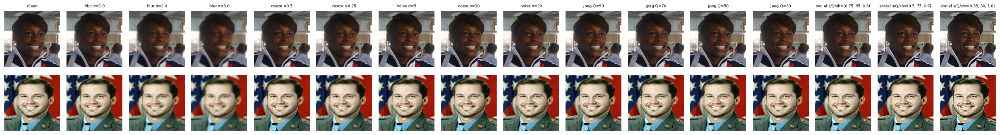

,blur@1,blur@2,blur@3,resize@1,resize@2,noise@1,noise@2,noise@3,jpeg@1,jpeg@2,jpeg@3,jpeg@4,social@1,social@2,social@3
mean PSNR (dB),38.3196,31.0639,27.6731,41.6532,32.8418,34.2136,28.3233,22.4966,44.7068,40.2823,37.995,35.5983,40.1681,33.6841,28.8495


In [12]:
import src.degrade as degrade
importlib.reload(degrade)
CONDS = degrade.all_conditions()
COND = {c["name"]: c for c in CONDS}
display(pd.DataFrame(CONDS)[["name", "type", "severity", "label"]].set_index("name").T)

def psnr(a, b):
    mse = np.mean((a.astype(np.float64) - b.astype(np.float64)) ** 2)
    return 99.0 if mse == 0 else 10 * np.log10(255 ** 2 / mse)

demo_rows = sample_per_class(meta[meta.detected == 1], 1).set_index("cls").loc[[REAL, "inpainting"]].reset_index()
fig, axes = plt.subplots(len(demo_rows), len(CONDS), figsize=(1.45 * len(CONDS), 1.7 * len(demo_rows)))
for i, r in enumerate(demo_rows.to_dict("records")):
    img = faces.read_rgb(r["crop_path"])
    for j, c in enumerate(CONDS):
        out = degrade.apply_degradation(img, c["name"], r["uid"])
        axes[i, j].imshow(out); axes[i, j].axis("off")
        if i == 0: axes[i, j].set_title(c["label"], fontsize=6.5)
fig.tight_layout(); savefig(fig, "degradation_grid"); plt.show()

# average PSNR per condition (how strong each degradation is)
smp = sample_per_class(meta, 25)
ps = {c["name"]: np.mean([psnr(im, degrade.apply_degradation(im, c["name"], u))
                          for im, u in ((faces.read_rgb(p), u) for p, u in zip(smp.crop_path, smp.uid))])
      for c in CONDS[1:]}
display(pd.Series(ps, name="mean PSNR (dB)").to_frame().T)

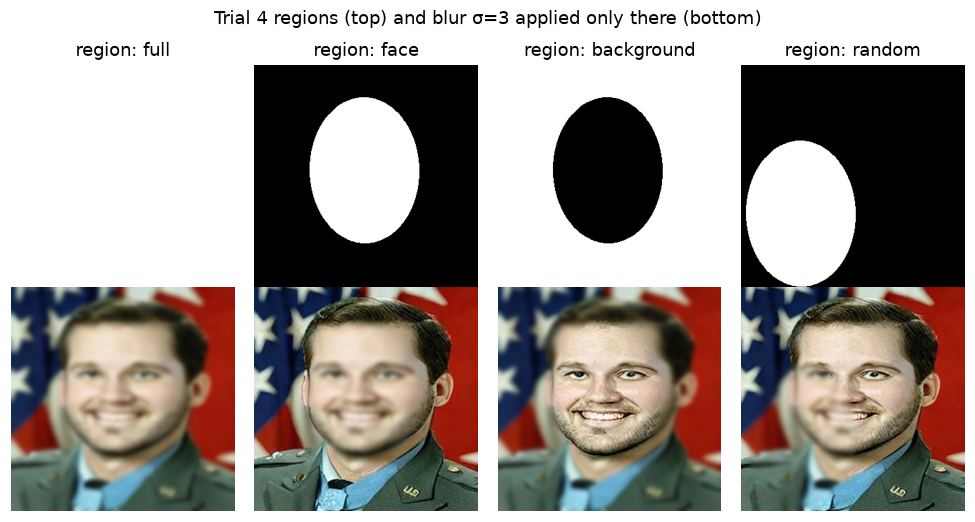

Face ROI covers 24.1% of the crop on average; random control region overlaps the face by 24.8% on average.


In [13]:
r = demo_rows.iloc[1].to_dict()
img = faces.read_rgb(r["crop_path"]); fm = faces.face_mask(r, CROP_SIZE, CROP_MARGIN)
fig, axes = plt.subplots(2, 4, figsize=(9, 4.8))
for j, reg in enumerate(T4_REGIONS):
    axes[0, j].imshow(degrade.region_mask(fm, reg, r["uid"]), cmap="gray", vmin=0, vmax=1); axes[0, j].set_title(f"region: {reg}")
    axes[1, j].imshow(degrade.apply_region_degradation(img, "blur@3", r["uid"], fm, reg))
    for a in axes[:, j]: a.axis("off")
fig.suptitle("Trial 4 regions (top) and blur σ=3 applied only there (bottom)"); fig.tight_layout()
savefig(fig, "region_degradation_examples"); plt.show()

ov = [degrade.random_region_mask(faces.face_mask(q, CROP_SIZE, CROP_MARGIN), np.random.default_rng(i))[1]
      for i, q in enumerate(sample_per_class(meta[meta.detected == 1], 50).to_dict("records"))]
areas = [faces.face_mask(q, CROP_SIZE, CROP_MARGIN).mean() for q in sample_per_class(meta[meta.detected == 1], 50).to_dict("records")]
print(f"Face ROI covers {np.mean(areas):.1%} of the crop on average; random control region overlaps the face by {np.mean(ov):.1%} on average.")

## 6 · Models, training loop, Grad-CAM, metrics
- **Classifiers** (timm, ImageNet-pretrained, single "fake" logit): ResNet-18 (`resnet18.tv_in1k`, 224 px) and Xception (`legacy_xception.tf_in1k`, the FaceForensics++ Xception, 299 px).
- **Training**: AdamW, warm-up + cosine LR, mixed precision on CUDA, BCE with `pos_weight` = #real/#fake (training sets are 1:1 to 3:1 fake:real), horizontal flip only – **no** blur/JPEG augmentation, so the baseline is a "clean-trained" detector. Early stopping on validation AUC; the decision threshold is fixed on the clean validation set (Youden's J) and kept fixed under degradation.
- **Grad-CAM** on the last convolutional feature map (`forward_features`), for the fake logit.
- **Metrics**: AUC (Mann-Whitney), accuracy / precision / recall / F1 at the fixed threshold, stratified bootstrap CIs, paired DeLong tests for AUC differences (analytic p-values, so hundreds of comparisons can survive Holm; bootstrap p-values bottom out at 1/n_boot), Holm correction, ESS = Spearman ρ between clean and degraded Grad-CAM maps, face energy = share of Grad-CAM mass inside the face ROI.

In [14]:
%%writefile src/metrics.py
"""Metrics and statistics: fast AUC, bootstrap CIs, paired bootstrap tests, Holm correction, ESS, face energy."""
import numpy as np
from scipy.stats import norm, rankdata


def fast_auc(y, s):
    """ROC-AUC via the Mann-Whitney U statistic (ties handled with mid-ranks)."""
    y = np.asarray(y).astype(bool)
    s = np.asarray(s, dtype=np.float64)
    n1, n0 = y.sum(), (~y).sum()
    if n1 == 0 or n0 == 0:
        return np.nan
    r = rankdata(s)
    return float((r[y].sum() - n1 * (n1 + 1) / 2) / (n1 * n0))


def best_threshold(y, s):
    """Threshold maximising balanced accuracy (Youden's J) – chosen once on the clean validation set."""
    y = np.asarray(y).astype(bool)
    s = np.asarray(s, dtype=np.float64)
    cand = np.unique(np.quantile(s, np.linspace(0.005, 0.995, 199)))
    best_t, best_j = 0.5, -1
    for t in cand:
        pred = s >= t
        j = pred[y].mean() + (~pred[~y]).mean() - 1
        if j > best_j:
            best_t, best_j = float(t), j
    return best_t


def classification_metrics(y, s, thr=0.5):
    y = np.asarray(y).astype(bool)
    pred = np.asarray(s) >= thr
    tp, fp = int((pred & y).sum()), int((pred & ~y).sum())
    fn, tn = int((~pred & y).sum()), int((~pred & ~y).sum())
    prec = tp / (tp + fp) if tp + fp else 0.0
    rec = tp / (tp + fn) if tp + fn else 0.0
    return dict(auc=fast_auc(y, s), acc=(tp + tn) / max(1, len(y)), precision=prec, recall=rec,
                f1=2 * prec * rec / (prec + rec) if prec + rec else 0.0,
                fpr=fp / (fp + tn) if fp + tn else 0.0, n=int(len(y)), n_fake=int(y.sum()))


def _strat_boot_idx(y, rng):
    y = np.asarray(y).astype(bool)
    pos, neg = np.flatnonzero(y), np.flatnonzero(~y)
    return np.concatenate([rng.choice(pos, len(pos)), rng.choice(neg, len(neg))])


def bootstrap_auc_ci(y, s, n_boot=1000, seed=0, alpha=0.05):
    rng = np.random.default_rng(seed)
    y, s = np.asarray(y), np.asarray(s)
    vals = [fast_auc(y[i], s[i]) for i in (_strat_boot_idx(y, rng) for _ in range(n_boot))]
    return float(np.nanpercentile(vals, 100 * alpha / 2)), float(np.nanpercentile(vals, 100 * (1 - alpha / 2)))


def delong_paired_p(y, s_a, s_b):
    """Two-sided p-value of DeLong's test for AUC(b) = AUC(a), two correlated scores on the same images
    (fast midrank version, Sun & Xu 2014). Analytic, so it is not floored at 1/n_boot like a bootstrap p-value –
    needed when hundreds of tests go through Holm."""
    y = np.asarray(y).astype(bool)
    m, n = int(y.sum()), int((~y).sum())
    if m < 2 or n < 2:
        return np.nan
    order = np.r_[np.flatnonzero(y), np.flatnonzero(~y)]
    X = np.vstack([np.asarray(s_a, np.float64), np.asarray(s_b, np.float64)])[:, order]
    tx, ty, tz = rankdata(X[:, :m], axis=1), rankdata(X[:, m:], axis=1), rankdata(X, axis=1)
    aucs = tz[:, :m].sum(1) / (m * n) - (m + 1) / (2 * n)
    v01 = (tz[:, :m] - tx) / n
    v10 = 1.0 - (tz[:, m:] - ty) / m
    S = np.cov(v01) / m + np.cov(v10) / n
    var = S[0, 0] + S[1, 1] - 2 * S[0, 1]
    if var <= 1e-15:
        return 1.0
    return float(2 * norm.sf(abs(aucs[1] - aucs[0]) / np.sqrt(var)))


def paired_bootstrap_delta(y, s_a, s_b, n_boot=1000, seed=0, alpha=0.05):
    """AUC(b) - AUC(a) on the same images. Returns delta, a stratified-bootstrap CI, the paired DeLong p-value (p)
    and the bootstrap p-value (p_boot, resolution 1/n_boot – kept for reference only)."""
    rng = np.random.default_rng(seed)
    y, s_a, s_b = np.asarray(y), np.asarray(s_a), np.asarray(s_b)
    delta = fast_auc(y, s_b) - fast_auc(y, s_a)
    d = np.empty(n_boot)
    for k in range(n_boot):
        i = _strat_boot_idx(y, rng)
        d[k] = fast_auc(y[i], s_b[i]) - fast_auc(y[i], s_a[i])
    p = 2 * min((d <= 0).mean(), (d >= 0).mean())
    return dict(delta=float(delta), lo=float(np.percentile(d, 100 * alpha / 2)),
                hi=float(np.percentile(d, 100 * (1 - alpha / 2))), p=delong_paired_p(y, s_a, s_b),
                p_boot=float(min(1.0, max(p, 1.0 / n_boot))))


def holm(pvals):
    """Holm–Bonferroni adjusted p-values (same order as input)."""
    p = np.asarray(pvals, dtype=np.float64)
    out = np.full_like(p, np.nan)
    ok = np.isfinite(p)
    idx = np.flatnonzero(ok)[np.argsort(p[ok])]
    m, running = len(idx), 0.0
    for rank, j in enumerate(idx):
        running = max(running, min(1.0, (m - rank) * p[j]))
        out[j] = running
    return out


def rowwise_spearman(A, B):
    """Spearman correlation between matching rows of A and B (N, D). Constant rows -> NaN.
    Used for the Explanation Stability Score (ESS) between clean and degraded Grad-CAM maps."""
    A = rankdata(np.asarray(A, dtype=np.float64).reshape(len(A), -1), axis=1)
    B = rankdata(np.asarray(B, dtype=np.float64).reshape(len(B), -1), axis=1)
    A -= A.mean(1, keepdims=True)
    B -= B.mean(1, keepdims=True)
    den = np.sqrt((A ** 2).sum(1) * (B ** 2).sum(1))
    with np.errstate(invalid="ignore", divide="ignore"):
        r = (A * B).sum(1) / den
    r[den == 0] = np.nan
    return r


def face_energy(cams, masks):
    """Share of Grad-CAM energy inside the face ROI, per image. cams, masks: (N, h, w)."""
    cams = np.asarray(cams, dtype=np.float64)
    masks = np.asarray(masks, dtype=np.float64)
    tot = cams.reshape(len(cams), -1).sum(1)
    with np.errstate(invalid="ignore", divide="ignore"):
        e = (cams * masks).reshape(len(cams), -1).sum(1) / tot
    e[tot <= 0] = np.nan
    return e

Overwriting src/metrics.py


In [15]:
%%writefile src/data.py
"""PyTorch dataset over cached face crops, with optional (region-restricted) degradation."""
import random

import cv2
import numpy as np
import torch
from torch.utils.data import Dataset

from . import degrade, faces

MASK_COLS = ["detected", "fx0", "fy0", "fx1", "fy1"] + [f"l{i}{a}" for i in range(5) for a in "xy"]


class FaceCropDataset(Dataset):
    """
    condition : 'clean' or e.g. 'jpeg@3' (applied at crop resolution, before resizing to the model input)
    region    : 'full' | 'face' | 'background' | 'random'   (Trial 4)
    train     : random horizontal flip
    aug_degrade_p : probability of a random degradation during training (optional remedy experiment)
    """

    def __init__(self, df, input_size, mean, std, condition="clean", region="full", train=False,
                 aug_degrade_p=0.0, crop_size=320, margin=1.7, feather=3.0):
        self.paths = df["crop_path"].tolist()
        self.labels = df["label"].to_numpy(np.float32)
        self.uids = df["uid"].tolist()
        self.meta = df[MASK_COLS].to_dict("records") if region != "full" else None
        self.input_size, self.condition, self.region = int(input_size), condition, region
        self.train, self.aug_p = train, aug_degrade_p
        self.mean = np.asarray(mean, np.float32).reshape(1, 1, 3)
        self.std = np.asarray(std, np.float32).reshape(1, 1, 3)
        self.crop_size, self.margin, self.feather = crop_size, margin, feather
        self.aug_conds = [c["name"] for c in degrade.all_conditions(include_clean=False)]

    def __len__(self):
        return len(self.paths)

    def load_rgb(self, i):
        return faces.read_rgb(self.paths[i])

    def __getitem__(self, i):
        img = self.load_rgb(i)
        if self.train and self.aug_p > 0 and random.random() < self.aug_p:
            img = degrade.apply_degradation(img, random.choice(self.aug_conds), f"{self.uids[i]}#{random.random()}")
        elif self.condition != "clean":
            fm = faces.face_mask(self.meta[i], img.shape[0], self.margin) if self.region != "full" else None
            img = degrade.apply_region_degradation(img, self.condition, self.uids[i], fm, self.region, self.feather)
        if self.train and random.random() < 0.5:
            img = img[:, ::-1]
        if img.shape[0] != self.input_size:
            interp = cv2.INTER_AREA if img.shape[0] > self.input_size else cv2.INTER_CUBIC
            img = cv2.resize(np.ascontiguousarray(img), (self.input_size, self.input_size), interpolation=interp)
        x = (img.astype(np.float32) / 255.0 - self.mean) / self.std
        return torch.from_numpy(np.ascontiguousarray(x.transpose(2, 0, 1))), torch.tensor(self.labels[i]), i


def make_loader(ds, batch_size, num_workers, shuffle=False, drop_last=False):
    return torch.utils.data.DataLoader(
        ds, batch_size=batch_size, shuffle=shuffle, drop_last=drop_last, num_workers=num_workers,
        pin_memory=torch.cuda.is_available(), persistent_workers=False,
        prefetch_factor=4 if num_workers > 0 else None)

Overwriting src/data.py


In [16]:
%%writefile src/train.py
"""Model construction (timm), training loop with early stopping, prediction, checkpoint I/O."""
import math
import time
from pathlib import Path

import numpy as np
import pandas as pd
import timm
import torch
import torch.nn as nn
from tqdm.auto import tqdm

from .data import FaceCropDataset, make_loader
from .metrics import fast_auc, best_threshold

# Each architecture: list of timm names to try (first one that exists in the installed timm wins).
ARCH_SPECS = {
    "resnet18": ["resnet18.tv_in1k", "resnet18"],
    "xception": ["legacy_xception.tf_in1k", "legacy_xception", "xception41.tf_in1k"],
}


def build_model(arch, pretrained=True):
    last_err = None
    for name in ARCH_SPECS[arch]:
        try:
            model = timm.create_model(name, pretrained=pretrained, num_classes=1)
            cfg = timm.data.resolve_model_data_config(model)
            return model, dict(timm_name=name, input_size=int(cfg["input_size"][-1]),
                               mean=tuple(cfg["mean"]), std=tuple(cfg["std"]))
        except Exception as e:      # unknown name / pretrained tag in this timm version
            last_err = e
    raise RuntimeError(f"Could not build {arch}: {last_err}")


def autocast_ctx(device, enabled=True):
    if device.type == "cuda" and enabled:
        return torch.autocast("cuda", dtype=torch.float16)
    return torch.autocast("cpu", enabled=False)


@torch.no_grad()
def predict(model, loader, device, amp=True):
    model.eval()
    out = np.zeros(len(loader.dataset), np.float32)
    for x, _, idx in loader:
        x = x.to(device, non_blocking=True).to(memory_format=torch.channels_last)
        with autocast_ctx(device, amp):
            logits = model(x).float().squeeze(1)
        out[idx.numpy()] = torch.sigmoid(logits).cpu().numpy()
    return out


def train_model(tag, arch, train_df, val_df, ckpt_dir, device, epochs=8, lr=1e-4, weight_decay=1e-4,
                batch_size=64, patience=2, num_workers=4, amp=True, aug_degrade_p=0.0, crop_size=320,
                margin=1.7, pretrained=True, seed=0, extra=None):
    ckpt_path = Path(ckpt_dir) / f"{tag}.pt"
    partial_path = Path(ckpt_dir) / f"{tag}.partial.pt"     # best epoch so far, while training is still running
    if ckpt_path.exists():
        print(f"[{tag}] checkpoint exists – skipping training")
        return ckpt_path
    Path(ckpt_dir).mkdir(parents=True, exist_ok=True)
    torch.manual_seed(seed)
    np.random.seed(seed)
    model, spec = build_model(arch, pretrained)
    model = model.to(device).to(memory_format=torch.channels_last)
    common = dict(input_size=spec["input_size"], mean=spec["mean"], std=spec["std"], crop_size=crop_size, margin=margin)
    tr_loader = make_loader(FaceCropDataset(train_df, train=True, aug_degrade_p=aug_degrade_p, **common),
                            batch_size, num_workers, shuffle=True, drop_last=True)
    va_loader = make_loader(FaceCropDataset(val_df, **common), batch_size, num_workers)

    n_pos = float(train_df["label"].sum())
    n_neg = float(len(train_df) - n_pos)
    crit = nn.BCEWithLogitsLoss(pos_weight=torch.tensor(n_neg / max(n_pos, 1.0), device=device))
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    total = epochs * len(tr_loader)
    warm = max(1, int(0.05 * total))
    sched = torch.optim.lr_scheduler.LambdaLR(
        opt, lambda s: min(1.0, (s + 1) / warm) * 0.5 * (1 + math.cos(math.pi * min(1.0, s / total))))
    use_amp = amp and device.type == "cuda"
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

    history, best_auc, best_state, bad, best_val_p, best_ep = [], -1.0, None, 0, None, 0

    def save_ckpt(path):
        thr = best_threshold(val_df["label"].to_numpy(), best_val_p)
        ckpt = dict(state_dict=best_state, arch=arch, spec=spec, threshold=thr, val_auc=best_auc, best_epoch=best_ep,
                    history=history, tag=tag, aug_degrade_p=aug_degrade_p, **(extra or {}))
        tmp = path.with_suffix(".tmp")
        torch.save(ckpt, tmp)
        tmp.replace(path)                                   # atomic: an interrupted save never leaves a broken file
        return thr

    for ep in range(1, epochs + 1):
        model.train()
        t0, run_loss, n = time.time(), 0.0, 0
        for x, y, _ in tqdm(tr_loader, desc=f"[{tag}] epoch {ep}/{epochs}", leave=False):
            x = x.to(device, non_blocking=True).to(memory_format=torch.channels_last)
            y = y.to(device, non_blocking=True)
            opt.zero_grad(set_to_none=True)
            with autocast_ctx(device, use_amp):
                loss = crit(model(x).float().squeeze(1), y)
            scaler.scale(loss).backward()
            scaler.step(opt)
            scaler.update()
            sched.step()
            run_loss += loss.item() * len(y)
            n += len(y)
        val_p = predict(model, va_loader, device, use_amp)
        val_auc = fast_auc(val_df["label"].to_numpy(), val_p)
        history.append(dict(epoch=ep, train_loss=run_loss / max(n, 1), val_auc=val_auc, sec=time.time() - t0))
        print(f"[{tag}] epoch {ep}: loss {run_loss / max(n, 1):.4f}  val AUC {val_auc:.4f}  ({time.time() - t0:.0f}s)")
        if best_state is None or val_auc > best_auc + 1e-4:
            best_auc, bad = val_auc, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            best_val_p, best_ep = val_p, ep
            save_ckpt(partial_path)
            print(f"[{tag}] new best epoch {ep} saved -> {partial_path.name}")
        else:
            bad += 1
            if bad >= patience:
                print(f"[{tag}] early stop")
                break

    thr = save_ckpt(ckpt_path)
    partial_path.unlink(missing_ok=True)
    pd.DataFrame(history).to_csv(Path(ckpt_dir) / f"{tag}_history.csv", index=False)
    print(f"[{tag}] best val AUC {best_auc:.4f} (epoch {best_ep}), threshold {thr:.3f} -> {ckpt_path.name}")
    del model
    if device.type == "cuda":
        torch.cuda.empty_cache()
    return ckpt_path


def load_model(ckpt_path, device):
    ckpt = torch.load(ckpt_path, map_location="cpu", weights_only=False)
    model = timm.create_model(ckpt["spec"]["timm_name"], pretrained=False, num_classes=1)
    model.load_state_dict(ckpt["state_dict"])
    model = model.to(device).to(memory_format=torch.channels_last).eval()
    return model, ckpt

Overwriting src/train.py


In [17]:
%%writefile src/cam.py
"""Grad-CAM for timm classifiers with a single 'fake' logit.

Uses model.forward_features / model.forward_head (available on every timm model), so the target layer is the
last convolutional feature map: ResNet-18 -> layer4, Xception -> the final separable conv block (act4).
"""
import numpy as np
import torch
import torch.nn.functional as F


def gradcam_batch(model, x, out_res=32):
    """Returns (cams[B,out_res,out_res] in [0,1], probs[B]). CAM is for the 'fake' logit."""
    model.eval()
    req = [p.requires_grad for p in model.parameters()]
    for p in model.parameters():
        p.requires_grad_(False)
    try:
        with torch.enable_grad():
            x = x.detach().requires_grad_(True)
            feats = model.forward_features(x)
            logits = model.forward_head(feats).float().reshape(-1)
            grads, = torch.autograd.grad(logits.sum(), feats)
            weights = grads.mean(dim=(2, 3), keepdim=True)
            cam = F.relu((weights * feats).sum(1, keepdim=True)).float()
    finally:
        for p, r in zip(model.parameters(), req):
            p.requires_grad_(r)
    cam = F.interpolate(cam, size=(out_res, out_res), mode="bilinear", align_corners=False)[:, 0]
    mx = cam.flatten(1).amax(1).clamp_min(1e-8)[:, None, None]
    return (cam / mx).detach().cpu().numpy(), torch.sigmoid(logits).detach().cpu().numpy()


def gradcam_loader(model, loader, device, out_res=32):
    n = len(loader.dataset)
    cams = np.zeros((n, out_res, out_res), np.float16)
    probs = np.zeros(n, np.float32)
    for x, _, idx in loader:
        c, p = gradcam_batch(model, x.to(device), out_res)
        cams[idx.numpy()] = c.astype(np.float16)
        probs[idx.numpy()] = p
    return cams, probs

Overwriting src/cam.py


In [18]:
import src.metrics as M, src.data as data, src.train as T, src.cam as C
for _m in (M, data, T, C):
    importlib.reload(_m)

TEST = meta[meta.split == "test"].reset_index(drop=True)
TEST_FP = hashlib.md5("".join(TEST.uid).encode()).hexdigest()[:8]
Y_TEST, CLS_TEST, DET_TEST = TEST.label.to_numpy(), TEST.cls.to_numpy(), TEST.detected.to_numpy().astype(bool)

def rows(split, gens):
    return meta[(meta.split == split) & meta.cls.isin([REAL] + list(gens))].reset_index(drop=True)

tag_single = lambda a, g: f"{a}__single-{g}"
tag_all    = lambda a: f"{a}__all"
tag_logo   = lambda a, g: f"{a}__logo-{g}"          # trained on every generator EXCEPT g

BEST_LR = {a: TRAIN_CFG["lr"] for a in ARCHS}

def train(tag, arch, gens, **overrides):
    cfg = {**TRAIN_CFG, "lr": BEST_LR[arch], "batch_size": BATCH_SIZE[arch], **overrides}
    return T.train_model(tag, arch, rows("train", gens), rows("val", gens), CKPT_DIR, DEVICE,
                         num_workers=NUM_WORKERS, crop_size=CROP_SIZE, margin=CROP_MARGIN, seed=SEED,
                         extra={"train_gens": list(gens)}, **cfg)

_MODELS, _CKMETA = {}, {}
def get_model(tag):
    """Keeps one model on the GPU at a time."""
    if tag not in _MODELS:
        _MODELS.clear()
        if DEVICE.type == "cuda": torch.cuda.empty_cache()
        _MODELS[tag] = T.load_model(CKPT_DIR / f"{tag}.pt", DEVICE)
    return _MODELS[tag]

def ck_meta(tag):
    if tag not in _CKMETA:
        ck = torch.load(CKPT_DIR / f"{tag}.pt", map_location="cpu", weights_only=False)
        ck.pop("state_dict"); _CKMETA[tag] = ck
    return _CKMETA[tag]

def preds(tag, cond="clean", region="full"):
    """P(fake) for every TEST image under a condition; cached on disk."""
    f = PRED_DIR / f"{tag}__{cond}__{region}__{TEST_FP}.npy"
    if f.exists():
        return np.load(f)
    model, ck = get_model(tag); s = ck["spec"]
    ds = data.FaceCropDataset(TEST, s["input_size"], s["mean"], s["std"], condition=cond, region=region,
                              crop_size=CROP_SIZE, margin=CROP_MARGIN)
    p = T.predict(model, data.make_loader(ds, EVAL_BATCH, NUM_WORKERS), DEVICE, TRAIN_CFG["amp"])
    np.save(f, p)
    return p

def gen_mask(g, detected_only=False):
    """TEST rows used to score generator g: all real test images + fakes of g."""
    m = np.isin(CLS_TEST, [REAL, g])
    return m & DET_TEST if detected_only else m

def evaluate(tag, g, cond="clean", region="full", ci=False, detected_only=False):
    m, p = gen_mask(g, detected_only), preds(tag, cond, region)
    r = M.classification_metrics(Y_TEST[m], p[m], ck_meta(tag)["threshold"])
    if ci:
        r["auc_lo"], r["auc_hi"] = M.bootstrap_auc_ci(Y_TEST[m], p[m], N_BOOT, SEED)
    return r

print(f"TEST: {len(TEST):,} images ({TEST.label.sum():,} fake) | fingerprint {TEST_FP}")

TEST: 19,936 images (14,952 fake) | fingerprint b6d414a1


In [19]:
# Sanity check: both backbones load with ImageNet weights and a batch flows through
for a in ARCHS:
    mdl, spec = T.build_model(a, pretrained=True)
    ds = data.FaceCropDataset(rows("train", GENS).sample(8, random_state=SEED), spec["input_size"], spec["mean"], spec["std"], train=True)
    x, y, _ = next(iter(data.make_loader(ds, 8, 0)))
    with torch.no_grad():
        out = mdl.eval()(x)
    print(f"{a:9s} timm={spec['timm_name']:24s} input={spec['input_size']} params={sum(p.numel() for p in mdl.parameters())/1e6:.1f}M "
          f"batch {tuple(x.shape)} -> {tuple(out.shape)}")
    del mdl

resnet18  timm=resnet18.tv_in1k         input=224 params=11.2M batch (8, 3, 224, 224) -> (8, 1)
xception  timm=legacy_xception.tf_in1k  input=299 params=20.8M batch (8, 3, 299, 299) -> (8, 1)


### 6.1 Hyper-parameter tuning
A short learning-rate sweep per backbone on the all-generator training set, scored by validation AUC (the test split is never used for tuning). The best LR is then used for every model. Set `RUN_HP_SWEEP = False` to skip and use `TRAIN_CFG["lr"]`.

In [20]:
if RUN_HP_SWEEP:
    hp = []
    for a in ARCHS:
        for lr in LR_GRID:
            tag = f"{a}__hp-lr{lr:g}"
            train(tag, a, GENS, lr=lr, epochs=HP_SWEEP_EPOCHS, patience=HP_SWEEP_EPOCHS)
            hp.append(dict(arch=a, lr=lr, val_auc=ck_meta(tag)["val_auc"]))
    HP = pd.DataFrame(hp); HP.to_csv(RES_DIR / "hp_sweep.csv", index=False)
    display(HP.pivot(index="lr", columns="arch", values="val_auc"))
    BEST_LR = HP.loc[HP.groupby("arch").val_auc.idxmax()].set_index("arch").lr.to_dict()
print("Learning rate per backbone:", BEST_LR)

Learning rate per backbone: {'resnet18': 0.0001, 'xception': 0.0001}


## 7 · Trial 1 — Baseline (Objective 1)
Train one detector per generator (`single-g`) and one on all three (`all`), for both backbones (8 models). Evaluate on **clean** test images of the same generator(s), plus the full cross-generator matrix as a first look at generalisation.

In [23]:
for a in ARCHS:
    for g in GENS:
        train(tag_single(a, g), a, [g])
    train(tag_all(a), a, GENS)

[resnet18__single-text2img] checkpoint exists – skipping training
[resnet18__single-inpainting] checkpoint exists – skipping training


[resnet18__single-insight] epoch 1/2:   0%|          | 0/2193 [00:02<?, ?it/s]

[resnet18__single-insight] epoch 1: loss 0.2503  val AUC 0.9880  (53s)
[resnet18__single-insight] new best epoch 1 saved -> resnet18__single-insight.partial.pt


[resnet18__single-insight] epoch 2/2:   0%|          | 0/2193 [00:02<?, ?it/s]

[resnet18__single-insight] epoch 2: loss 0.1161  val AUC 0.9930  (53s)
[resnet18__single-insight] new best epoch 2 saved -> resnet18__single-insight.partial.pt
[resnet18__single-insight] best val AUC 0.9930 (epoch 2), threshold 0.469 -> resnet18__single-insight.pt


[resnet18__all] epoch 1/2:   0%|          | 0/4386 [00:02<?, ?it/s]

... (15 outputs left out)

[xception__all] epoch 1/2:   0%|          | 0/4386 [00:02<?, ?it/s]

[xception__all] epoch 1: loss 0.1036  val AUC 0.9956  (526s)
[xception__all] new best epoch 1 saved -> xception__all.partial.pt


[xception__all] epoch 2/2:   0%|          | 0/4386 [00:02<?, ?it/s]

[xception__all] epoch 2: loss 0.0312  val AUC 0.9971  (521s)
[xception__all] new best epoch 2 saved -> xception__all.partial.pt
[xception__all] best val AUC 0.9971 (epoch 2), threshold 0.451 -> xception__all.pt


In-distribution performance (clean test images, 95% bootstrap CI for AUC):


auc  auc_lo  auc_hi     acc  precision  recall      f1     fpr
arch     train_set         test_gen                                                                     
resnet18 single-text2img   text2img    0.9995  0.9993  0.9997  0.9886     0.9959  0.9811  0.9885  0.0040
         single-inpainting inpainting  0.9977  0.9971  0.9981  0.9760     0.9705  0.9819  0.9762  0.0299
         single-insight    insight     0.9933  0.9921  0.9943  0.9601     0.9699  0.9496  0.9597  0.0295
         all               text2img    0.9970  0.9965  0.9976  0.9713     0.9588  0.9850  0.9717  0.0423
                           inpainting  0.9918  0.9906  0.9929  0.9535     0.9573  0.9492  0.9533  0.0423
                           insight     0.9869  0.9852  0.9885  0.9447     0.9565  0.9318  0.9440  0.0423
xception single-text2img   text2img    0.9998  0.9997  0.9999  0.9941     0.9946  0.9936  0.9941  0.0054
         single-inpainting inpainting  0.9993  0.9991  0.9995  0.9861     0.9925  0.9795  0.9860  0.0074
         single-insight    insight     0.9965  0.9957  0.9972  0.9728     0.9725  0.9731  0.9728  0.0275
         all               text2img    0.9991  0.9987  0.9994  0.9854     0.9786  0.9924  0.9855  0.0217
                           inpainting  0.9978  0.9972  0.9984  0.9797     0.9784  0.9811  0.9798  0.0217
                           insight     0.9946  0.9936  0.9955  0.9634     0.9777  0.9484  0.9628  0.0217

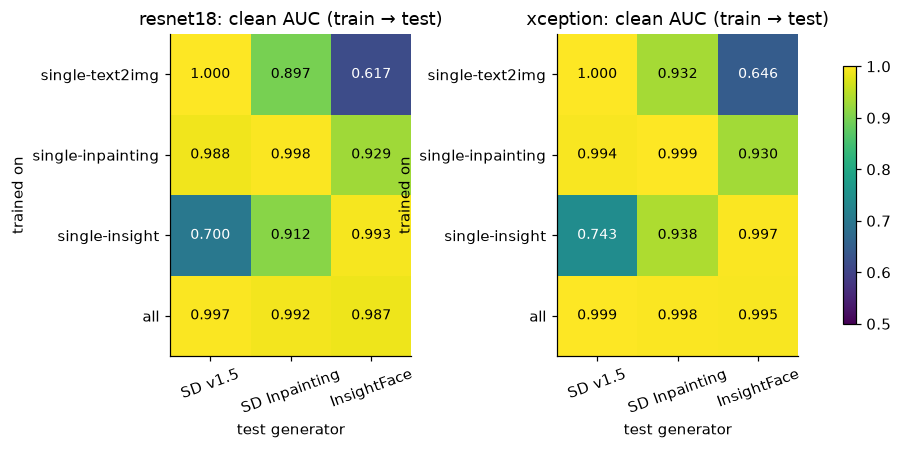

In [24]:
t1 = []
for a in ARCHS:
    for train_set, gens in [(f"single-{g}", [g]) for g in GENS] + [("all", GENS)]:
        tag = f"{a}__{train_set}"
        for g in GENS:
            t1.append(dict(arch=a, train_set=train_set, test_gen=g, in_dist=g in gens,
                           **evaluate(tag, g, ci=g in gens)))
T1 = pd.DataFrame(t1); T1.to_csv(RES_DIR / "trial1_baseline.csv", index=False)

print("In-distribution performance (clean test images, 95% bootstrap CI for AUC):")
display(T1[T1.in_dist][["arch", "train_set", "test_gen", "auc", "auc_lo", "auc_hi", "acc", "precision", "recall", "f1", "fpr"]]
        .set_index(["arch", "train_set", "test_gen"]))

fig, axes = plt.subplots(1, len(ARCHS), figsize=(5.2 * len(ARCHS), 3.8))
for ax, a in zip(np.atleast_1d(axes), ARCHS):
    mat = T1[T1.arch == a].pivot(index="train_set", columns="test_gen", values="auc").reindex(
        index=[f"single-{g}" for g in GENS] + ["all"], columns=GENS)
    im = ax.imshow(mat.values, vmin=0.5, vmax=1, cmap="viridis")
    ax.set_xticks(range(len(GENS)), [GENERATORS[g] for g in GENS], rotation=20)
    ax.set_yticks(range(len(mat)), mat.index)
    for i in range(mat.shape[0]):
        for j in range(mat.shape[1]):
            ax.text(j, i, f"{mat.values[i, j]:.3f}", ha="center", va="center", color="w" if mat.values[i, j] < .8 else "k", fontsize=9)
    ax.set(title=f"{a}: clean AUC (train → test)", xlabel="test generator", ylabel="trained on")
fig.colorbar(im, ax=axes, shrink=.8); savefig(fig, "trial1_cross_generator_auc"); plt.show()

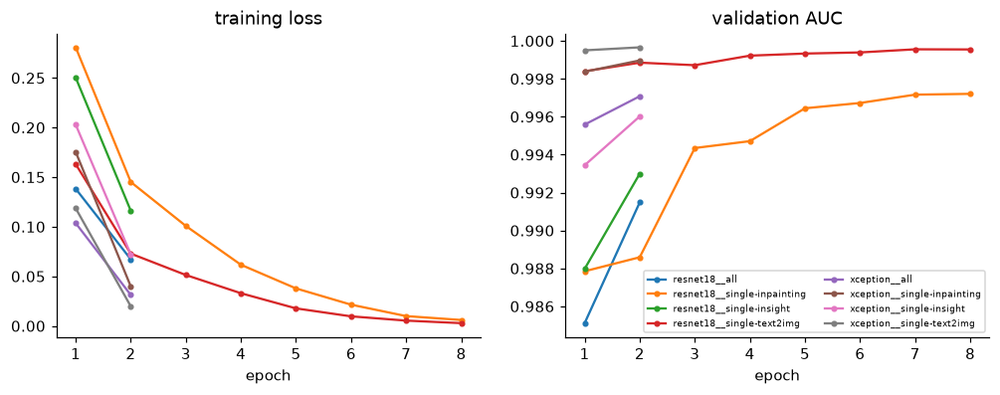

In [25]:
# Training curves
hist = []
for f in CKPT_DIR.glob("*_history.csv"):
    if "__hp-" in f.name: continue
    h = pd.read_csv(f); h["tag"] = f.name.replace("_history.csv", ""); hist.append(h)
if hist:
    H = pd.concat(hist)
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
    for tag, h in H.groupby("tag"):
        axes[0].plot(h.epoch, h.train_loss, marker=".", label=tag); axes[1].plot(h.epoch, h.val_auc, marker=".", label=tag)
    axes[0].set(title="training loss", xlabel="epoch"); axes[1].set(title="validation AUC", xlabel="epoch")
    axes[1].legend(fontsize=6, ncol=2); savefig(fig, "training_curves"); plt.show()

## 8 · Trial 2 — Unseen generator × degradation (Objective 2)
Leave-one-generator-out (LOGO): `logo-g` is trained on the other two generators. Each LOGO model is evaluated on all three generators – the held-out one is **unseen**, the other two are **seen** – under clean and all 15 degraded conditions. This gives the four cells of the "two roads" design on the *same test images*:

| | clean | degraded |
|---|---|---|
| **seen** generator | reference | road 2: degradation |
| **unseen** generator | road 1: new generator | both at once |

In [26]:
for a in ARCHS:
    for g in GENS:
        train(tag_logo(a, g), a, [h for h in GENS if h != g])

[resnet18__logo-text2img] epoch 1/2:   0%|          | 0/3289 [00:02<?, ?it/s]

[resnet18__logo-text2img] epoch 1: loss 0.1924  val AUC 0.9786  (78s)
[resnet18__logo-text2img] new best epoch 1 saved -> resnet18__logo-text2img.partial.pt


[resnet18__logo-text2img] epoch 2/2:   0%|          | 0/3289 [00:02<?, ?it/s]

[resnet18__logo-text2img] epoch 2: loss 0.0974  val AUC 0.9900  (76s)
[resnet18__logo-text2img] new best epoch 2 saved -> resnet18__logo-text2img.partial.pt
[resnet18__logo-text2img] best val AUC 0.9900 (epoch 2), threshold 0.436 -> resnet18__logo-text2img.pt


[resnet18__logo-inpainting] epoch 1/2:   0%|          | 0/3289 [00:02<?, ?it/s]

[resnet18__logo-inpainting] epoch 1: loss 0.1747  val AUC 0.9882  (76s)
[resnet18__logo-inpainting] new best epoch 1 saved -> resnet18__logo-inpainting.partial.pt


... (14 outputs left out)

[xception__logo-insight] epoch 1/2:   0%|          | 0/3289 [00:02<?, ?it/s]

[xception__logo-insight] epoch 1: loss 0.1039  val AUC 0.9990  (392s)
[xception__logo-insight] new best epoch 1 saved -> xception__logo-insight.partial.pt


[xception__logo-insight] epoch 2/2:   0%|          | 0/3289 [00:02<?, ?it/s]

[xception__logo-insight] epoch 2: loss 0.0209  val AUC 0.9995  (391s)
[xception__logo-insight] new best epoch 2 saved -> xception__logo-insight.partial.pt
[xception__logo-insight] best val AUC 0.9995 (epoch 2), threshold 0.481 -> xception__logo-insight.pt


In [27]:
t2 = []
for a in ARCHS:
    for held in GENS:
        tag, thr = tag_logo(a, held), ck_meta(tag_logo(a, held))["threshold"]
        for c in tqdm(CONDS, desc=tag, leave=False):
            p = preds(tag, c["name"])
            for g in GENS:
                m = gen_mask(g)
                t2.append(dict(arch=a, heldout=held, test_gen=g, seen=g != held, cond=c["name"], type=c["type"],
                               severity=c["severity"], rel_severity=c["rel_severity"],
                               **M.classification_metrics(Y_TEST[m], p[m], thr)))
T2 = pd.DataFrame(t2)
KEYS = ["arch", "heldout", "test_gen"]
T2 = T2.merge(T2[T2.cond == "clean"][KEYS + ["auc"]].rename(columns={"auc": "auc_clean"}), on=KEYS)
T2["d_auc"] = T2.auc - T2.auc_clean
T2.to_csv(RES_DIR / "trial2_grid.csv", index=False)

# Road 1 alone: clean AUC on each generator when seen vs unseen (with CIs)
rows1 = []
for a in ARCHS:
    for g in GENS:
        for held in GENS:
            r = evaluate(tag_logo(a, held), g, ci=True)
            rows1.append(dict(arch=a, test_gen=g, model=f"logo-{held}", status="UNSEEN" if held == g else "seen", **r))
T2clean = pd.DataFrame(rows1); T2clean.to_csv(RES_DIR / "trial2_clean_seen_vs_unseen.csv", index=False)
display(T2clean[["arch", "test_gen", "model", "status", "auc", "auc_lo", "auc_hi", "acc", "recall", "fpr"]].set_index(["arch", "test_gen", "model"]))

resnet18__logo-text2img:   0%|          | 0/16 [00:00<?, ?it/s]

resnet18__logo-inpainting:   0%|          | 0/16 [00:00<?, ?it/s]

resnet18__logo-insight:   0%|          | 0/16 [00:00<?, ?it/s]

xception__logo-text2img:   0%|          | 0/16 [00:00<?, ?it/s]

xception__logo-inpainting:   0%|          | 0/16 [00:00<?, ?it/s]

xception__logo-insight:   0%|          | 0/16 [00:00<?, ?it/s]

status     auc  auc_lo  auc_hi     acc  recall     fpr
arch     test_gen   model                                                                  
resnet18 text2img   logo-text2img    UNSEEN  0.9686  0.9658  0.9716  0.8862  0.8182  0.0457
                    logo-inpainting    seen  0.9967  0.9961  0.9974  0.9707  0.9747  0.0333
                    logo-insight       seen  0.9986  0.9982  0.9990  0.9820  0.9872  0.0231
         inpainting logo-text2img      seen  0.9922  0.9910  0.9933  0.9562  0.9581  0.0457
                    logo-inpainting  UNSEEN  0.9690  0.9660  0.9717  0.8880  0.8094  0.0333
                    logo-insight       seen  0.9956  0.9947  0.9964  0.9674  0.9579  0.0231
         insight    logo-text2img      seen  0.9887  0.9871  0.9901  0.9474  0.9406  0.0457
                    logo-inpainting    seen  0.9896  0.9879  0.9911  0.9517  0.9368  0.0333
                    logo-insight     UNSEEN  0.9142  0.9084  0.9193  0.7580  0.5391  0.0231
xception text2img   logo-text2img    UNSEEN  0.9847  0.9829  0.9865  0.9203  0.8630  0.0223
                    logo-inpainting    seen  0.9989  0.9986  0.9993  0.9859  0.9860  0.0142
                    logo-insight       seen  0.9997  0.9995  0.9999  0.9934  0.9972  0.0104
         inpainting logo-text2img      seen  0.9979  0.9974  0.9984  0.9800  0.9823  0.0223
                    logo-inpainting  UNSEEN  0.9862  0.9845  0.9879  0.9133  0.8409  0.0142
                    logo-insight       seen  0.9990  0.9986  0.9993  0.9885  0.9874  0.0104
         insight    logo-text2img      seen  0.9954  0.9945  0.9962  0.9668  0.9559  0.0223
                    logo-inpainting    seen  0.9942  0.9931  0.9952  0.9611  0.9364  0.0142
                    logo-insight     UNSEEN  0.9099  0.9043  0.9154  0.7089  0.4282  0.0104

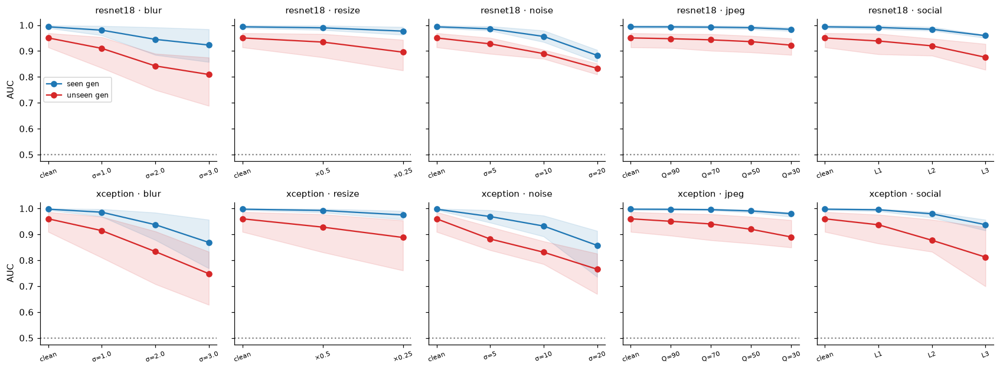

In [28]:
# AUC vs severity: seen (mean over the two LOGO models that saw the generator) vs unseen
types = list(degrade.DEGRADATIONS)
fig, axes = plt.subplots(len(ARCHS), len(types), figsize=(3.1 * len(types), 2.9 * len(ARCHS)), sharey=True, squeeze=False)
for i, a in enumerate(ARCHS):
    for j, t in enumerate(types):
        ax = axes[i, j]
        sub = T2[(T2.arch == a) & ((T2.type == t) | (T2.cond == "clean"))]
        for seen, col in [(True, "tab:blue"), (False, "tab:red")]:
            s = sub[sub.seen == seen].groupby("severity").auc.agg(["mean", "min", "max"])
            ax.plot(s.index, s["mean"], marker="o", color=col, label="seen gen" if seen else "unseen gen")
            ax.fill_between(s.index, s["min"], s["max"], color=col, alpha=.12)
        ax.set_xticks(range(len(degrade.DEGRADATIONS[t]["levels"]) + 1),
                      ["clean"] + [degrade.DEGRADATIONS[t]["fmt"].format(v) if t != "social" else f"L{k+1}"
                                   for k, v in enumerate(degrade.DEGRADATIONS[t]["levels"])], fontsize=7, rotation=20)
        ax.axhline(.5, ls=":", c="gray"); ax.set_title(f"{a} · {t}", fontsize=10)
        if j == 0: ax.set_ylabel("AUC")
axes[0, 0].legend(fontsize=8); fig.tight_layout(); savefig(fig, "trial2_auc_vs_severity"); plt.show()

cond  seen_clean  unseen_clean  seen_deg  unseen_deg  drop_unseen  drop_deg  drop_both  interaction
arch     test_gen   type                                                                                                           
resnet18 text2img   blur      blur@2      0.9977        0.9686    0.9836      0.8883       0.0290    0.0141     0.1094       0.0663
                    resize  resize@1      0.9977        0.9686    0.9967      0.9659       0.0290    0.0010     0.0318       0.0018
                    noise    noise@2      0.9977        0.9686    0.9680      0.8951       0.0290    0.0296     0.1025       0.0439
                    jpeg      jpeg@3      0.9977        0.9686    0.9950      0.9557       0.0290    0.0026     0.0420       0.0103
                    social  social@2      0.9977        0.9686    0.9903      0.9301       0.0290    0.0073     0.0676       0.0312
         inpainting blur      blur@2      0.9939        0.9690    0.9532      0.8897       0.0249    0.0407     0.1042       0.0386
                    resize  resize@1      0.9939        0.9690    0.9904      0.9625       0.0249    0.0035     0.0314       0.0030
                    noise    noise@2      0.9939        0.9690    0.9581      0.9048       0.0249    0.0358     0.0891       0.0284
                    jpeg      jpeg@3      0.9939        0.9690    0.9895      0.9583       0.0249    0.0044     0.0356       0.0062
                    social  social@2      0.9939        0.9690    0.9828      0.9478       0.0249    0.0111     0.0461       0.0101
         insight    blur      blur@2      0.9891        0.9142    0.8983      0.7495       0.0749    0.0908     0.2397       0.0739
                    resize  resize@1      0.9891        0.9142    0.9819      0.8755       0.0749    0.0073     0.1136       0.0314
                    noise    noise@2      0.9891        0.9142    0.9432      0.8701       0.0749    0.0459     0.1191      -0.0018
                    jpeg      jpeg@3      0.9891        0.9142    0.9858      0.8948       0.0749    0.0033     0.0943       0.0160
                    social  social@2      0.9891        0.9142    0.9794      0.8822       0.0749    0.0097     0.1069       0.0223
xception text2img   blur      blur@2      0.9993        0.9847    0.9781      0.8810       0.0146    0.0213     0.1183       0.0824
                    resize  resize@1      0.9993        0.9847    0.9979      0.9775       0.0146    0.0015     0.0218       0.0058
                    noise    noise@2      0.9993        0.9847    0.9386      0.7852       0.0146    0.0607     0.2141       0.1387
                    jpeg      jpeg@3      0.9993        0.9847    0.9947      0.9269       0.0146    0.0047     0.0724       0.0532
                    social  social@2      0.9993        0.9847    0.9854      0.8421       0.0146    0.0139     0.1573       0.1287
         inpainting blur      blur@2      0.9985        0.9862    0.9532      0.9120       0.0122    0.0452     0.0864       0.0290
                    resize  resize@1      0.9985        0.9862    0.9949      0.9758       0.0122    0.0036     0.0226       0.0069
                    noise    noise@2      0.9985        0.9862    0.9491      0.8735       0.0122    0.0494     0.1250       0.0634
                    jpeg      jpeg@3      0.9985        0.9862    0.9889      0.9680       0.0122    0.0096     0.0305       0.0087
                    social  social@2      0.9985        0.9862    0.9719      0.9570       0.0122    0.0265     0.0415       0.0028
         insight    blur      blur@2      0.9948        0.9099    0.8815      0.7079       0.0849    0.1133     0.2869       0.0887
                    resize  resize@1      0.9948        0.9099    0.9847      0.8310       0.0849    0.0100     0.1638       0.0689
                    noise    noise@2      0.9948        0.9099    0.9093      0.8348       0.0849    0.0855     0.1599      -0.0105
                    jpeg      jpeg@3      0.9948        0.9099    0.9883

Mean drop: unseen 0.0401 | degradation 0.0257 | both 0.1042
Interaction (both − unseen − degradation): mean +0.0383, Wilcoxon p = 1.3e-07  (note: AUC cannot fall far below 0.5, which pushes large combined drops toward sub-additivity)


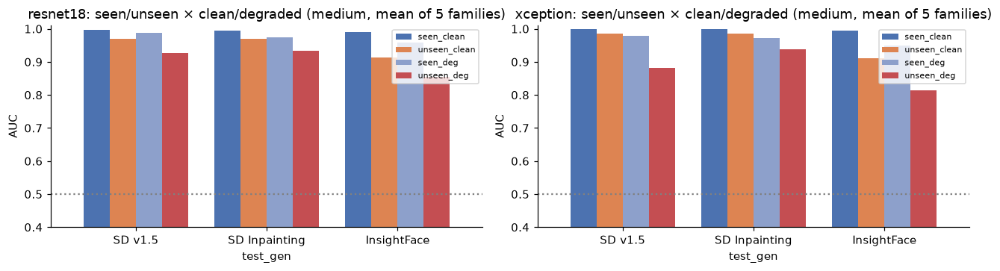

In [29]:
# The 2x2 per generator / degradation family at medium severity, and the interaction ("both at once")
A = T2.set_index(["arch", "heldout", "test_gen", "cond"]).auc
cells = []
for a in ARCHS:
    for g in GENS:
        seen_m = [h for h in GENS if h != g]
        sc = np.mean([A[(a, h, g, "clean")] for h in seen_m]); uc = A[(a, g, g, "clean")]
        for t, cond in MEDIUM.items():
            sd = np.mean([A[(a, h, g, cond)] for h in seen_m]); ud = A[(a, g, g, cond)]
            cells.append(dict(arch=a, test_gen=g, type=t, cond=cond, seen_clean=sc, unseen_clean=uc, seen_deg=sd, unseen_deg=ud,
                              drop_unseen=sc - uc, drop_deg=sc - sd, drop_both=sc - ud))
TWO = pd.DataFrame(cells)
TWO["interaction"] = TWO.drop_both - TWO.drop_unseen - TWO.drop_deg     # >0: worse than the sum of the two drops
TWO.to_csv(RES_DIR / "trial2_two_roads_2x2.csv", index=False)
display(TWO.set_index(["arch", "test_gen", "type"]).round(4))

w = stats.wilcoxon(TWO.interaction) if len(TWO) > 5 else None
print(f"Mean drop: unseen {TWO.drop_unseen.mean():.4f} | degradation {TWO.drop_deg.mean():.4f} | both {TWO.drop_both.mean():.4f}")
if w: print(f"Interaction (both − unseen − degradation): mean {TWO.interaction.mean():+.4f}, Wilcoxon p = {w.pvalue:.3g}  "
            "(note: AUC cannot fall far below 0.5, which pushes large combined drops toward sub-additivity)")

fig, axes = plt.subplots(1, len(ARCHS), figsize=(6 * len(ARCHS), 3.4), squeeze=False)
for ax, a in zip(axes[0], ARCHS):
    s = TWO[TWO.arch == a].groupby("test_gen")[["seen_clean", "unseen_clean", "seen_deg", "unseen_deg"]].mean().reindex(GENS)
    s.plot.bar(ax=ax, color=["#4C72B0", "#DD8452", "#8DA0CB", "#C44E52"], width=.8)
    ax.set(ylim=(.4, 1.01), ylabel="AUC", title=f"{a}: seen/unseen × clean/degraded (medium, mean of 5 families)")
    ax.set_xticklabels([GENERATORS[g] for g in GENS], rotation=0); ax.axhline(.5, ls=":", c="gray"); ax.legend(fontsize=7)
fig.tight_layout(); savefig(fig, "trial2_two_roads_bars"); plt.show()

In [30]:
# Statistical tests: (a) unseen vs seen model on the same images, (b) clean vs every degraded condition
tests_unseen = []
for a in ARCHS:
    for g in GENS:
        m = gen_mask(g); y = Y_TEST[m]; pu = preds(tag_logo(a, g))[m]
        for h in [h for h in GENS if h != g]:
            d = M.paired_bootstrap_delta(y, preds(tag_logo(a, h))[m], pu, N_BOOT, SEED)
            tests_unseen.append(dict(arch=a, test_gen=g, seen_model=f"logo-{h}", **d))
TU = pd.DataFrame(tests_unseen); TU["p_holm"] = M.holm(TU.p)
print("AUC(unseen model) − AUC(seen model) on the same clean test images:")
display(TU.set_index(["arch", "test_gen", "seen_model"]))

tests_deg = []
for a in ARCHS:
    for held in GENS:
        tag = tag_logo(a, held); p0 = preds(tag)
        for c in CONDS[1:]:
            p1 = preds(tag, c["name"])
            for g in GENS:
                m = gen_mask(g)
                tests_deg.append(dict(arch=a, heldout=held, test_gen=g, seen=g != held, cond=c["name"],
                                      **M.paired_bootstrap_delta(Y_TEST[m], p0[m], p1[m], N_BOOT_GRID, SEED)))
TD = pd.DataFrame(tests_deg); TD["p_holm"] = M.holm(TD.p)
TD.to_csv(RES_DIR / "trial2_degradation_tests.csv", index=False)
print(f"Clean→degraded AUC changes significant after Holm (α=.05): {(TD.p_holm < .05).sum()} / {len(TD)}")
display(TD.groupby(["arch", "seen", "cond"]).agg(mean_delta=("delta", "mean"), n_sig=("p_holm", lambda p: int((p < .05).sum()))).unstack("seen").round(4))

AUC(unseen model) − AUC(seen model) on the same clean test images:


delta      lo      hi            p  p_boot       p_holm
arch     test_gen   seen_model                                                               
resnet18 text2img   logo-inpainting -0.0281 -0.0308 -0.0254   1.1644e-93   0.001   8.1511e-93
                    logo-insight    -0.0300 -0.0327 -0.0271  7.6203e-100   0.001   6.0962e-99
         inpainting logo-text2img   -0.0232 -0.0255 -0.0209   7.6951e-84   0.001   3.8476e-83
                    logo-insight    -0.0266 -0.0294 -0.0241   6.2414e-92   0.001   3.7448e-91
         insight    logo-text2img   -0.0745 -0.0791 -0.0699  2.2811e-205   0.001  2.2811e-204
                    logo-inpainting -0.0754 -0.0803 -0.0706  7.9199e-197   0.001  7.1279e-196
xception text2img   logo-inpainting -0.0142 -0.0159 -0.0125   6.6820e-62   0.001   2.0046e-61
                    logo-insight    -0.0150 -0.0168 -0.0132   2.9164e-63   0.001   1.1666e-62
         inpainting logo-text2img   -0.0117 -0.0133 -0.0103   3.1763e-54   0.001   6.3526e-54
                    logo-insight    -0.0128 -0.0145 -0.0112   8.7348e-54   0.001   8.7348e-54
         insight    logo-text2img   -0.0855 -0.0909 -0.0803  2.7007e-215   0.001  3.2409e-214
                    logo-inpainting -0.0843 -0.0896 -0.0789  1.3145e-209   0.001  1.4460e-208

Clean→degraded AUC changes significant after Holm (α=.05): 266 / 270


mean_delta         n_sig      
seen                   False   True  False True 
arch     cond                                   
resnet18 blur@1      -0.0403 -0.0130     3     6
         blur@2      -0.1081 -0.0485     3     6
         blur@3      -0.1412 -0.0704     3     6
         jpeg@1      -0.0030 -0.0003     3     4
         jpeg@2      -0.0074 -0.0013     3     6
         jpeg@3      -0.0143 -0.0035     3     6
         jpeg@4      -0.0280 -0.0098     3     6
         noise@1     -0.0229 -0.0079     3     6
         noise@2     -0.0606 -0.0371     3     6
         noise@3     -0.1174 -0.1103     3     6
         resize@1    -0.0160 -0.0039     3     6
         resize@2    -0.0550 -0.0167     3     6
         social@1    -0.0119 -0.0025     3     6
         social@2    -0.0306 -0.0094     3     6
         social@3    -0.0748 -0.0342     3     6
xception blur@1      -0.0457 -0.0118     3     6
         blur@2      -0.1266 -0.0599     3     6
         blur@3      -0.2121 -0.1285     3     6
         jpeg@1      -0.0097 -0.0005     3     4
         jpeg@2      -0.0200 -0.0019     3     6
         jpeg@3      -0.0404 -0.0069     3     6
         jpeg@4      -0.0704 -0.0175     3     6
         noise@1     -0.0779 -0.0284     3     6
         noise@2     -0.1291 -0.0652     3     6
         noise@3     -0.1948 -0.1400     3     6
         resize@1    -0.0322 -0.0050     3     6
         resize@2    -0.0722 -0.0223     3     6
         social@1    -0.0231 -0.0023     3     6
         social@2    -0.0830 -0.0180     3     6
         social@3    -0.1479 -0.0600     3     6

## 9 · Trial 3 — Explanation drift (Objective 3)
Grad-CAM for a stratified sample of test images (`CAM_N_PER_CLASS` per class, detected faces only) under every condition, for the three LOGO models and the all-generator model of each backbone.

Per image we record
- **face energy** = share of Grad-CAM mass inside the face ROI (and **face-focus lift** = face energy ÷ face area; 1 = no preference),
- **ESS** = Spearman ρ between the clean and degraded Grad-CAM maps (1 = explanation unchanged).

Then three analyses:
1. **Drift ↔ performance**: across all (model, generator, condition) cells, does lower ESS go with a larger AUC drop?
2. **Face focus on the two roads**: for each fake image, face energy under the model that has seen its generator vs. the model that has not, clean vs. degraded (paired Wilcoxon tests).
3. **Same evidence lost?** For each fake we build two *evidence-shift maps* relative to the all-generator model on the clean image: Δ<sub>unseen</sub> = CAM(LOGO model, clean) − CAM(all model, clean) and Δ<sub>degr</sub> = CAM(all model, degraded) − CAM(all model, clean). If both roads remove the same evidence, Δ<sub>unseen</sub> and Δ<sub>degr</sub> correlate on the same image above a shuffled-image baseline.

In [31]:
CAM_DF = sample_per_class(TEST[TEST.detected == 1], CAM_N_PER_CLASS).reset_index(drop=True)
CAM_FP = hashlib.md5("".join(CAM_DF.uid).encode()).hexdigest()[:8]
_mask_recs = CAM_DF[data.MASK_COLS].to_dict("records")
MASKS = np.stack([cv2.resize(faces.face_mask(r, CROP_SIZE, CROP_MARGIN), (CAM_RES, CAM_RES), interpolation=cv2.INTER_AREA)
                  for r in _mask_recs]).astype(np.float32)
AREA = MASKS.reshape(len(MASKS), -1).mean(1)
CAM_CLS = CAM_DF.cls.to_numpy()

def cams(tag, cond="clean", region="full"):
    f = CAM_DIR / f"{tag}__{cond}__{region}__{CAM_FP}.npz"
    if f.exists():
        z = np.load(f); return z["cam"], z["prob"]
    model, ck = get_model(tag); s = ck["spec"]
    ds = data.FaceCropDataset(CAM_DF, s["input_size"], s["mean"], s["std"], condition=cond, region=region,
                              crop_size=CROP_SIZE, margin=CROP_MARGIN)
    c, p = C.gradcam_loader(model, data.make_loader(ds, EVAL_BATCH, NUM_WORKERS), DEVICE, CAM_RES)
    np.savez_compressed(f, cam=c, prob=p)
    return c, p

CAM_TAGS = [(a, tag_logo(a, g), g) for a in ARCHS for g in GENS] + [(a, tag_all(a), "none") for a in ARCHS]
for a, tag, held in tqdm(CAM_TAGS, desc="Grad-CAM"):
    for c in CONDS:
        cams(tag, c["name"])
print(f"Grad-CAM sample: {len(CAM_DF)} images; mean face area {AREA.mean():.1%} of the crop")

Grad-CAM:   0%|          | 0/8 [00:00<?, ?it/s]

Grad-CAM sample: 1200 images; mean face area 24.4% of the crop


In [32]:
recs = []
for a, tag, held in CAM_TAGS:
    c0, p0 = cams(tag)
    fe0 = M.face_energy(c0, MASKS)
    for c in CONDS[1:]:
        c1, p1 = cams(tag, c["name"])
        d = pd.DataFrame(dict(uid=CAM_DF.uid, cls=CAM_DF.cls, label=CAM_DF.label, area=AREA, p_clean=p0, p_deg=p1,
                              fe_clean=fe0, fe_deg=M.face_energy(c1, MASKS), ess=M.rowwise_spearman(c0, c1)))
        d["arch"], d["tag"], d["heldout"] = a, tag, held
        d["cond"], d["type"], d["severity"], d["rel_severity"] = c["name"], c["type"], c["severity"], c["rel_severity"]
        recs.append(d)
T3 = pd.concat(recs, ignore_index=True)
T3["model"] = np.where(T3.heldout == "none", "all", "logo")
T3["status"] = np.where(T3.label == 0, "real", np.where((T3.model == "all") | (T3.cls != T3.heldout), "seen", "unseen"))
T3["dfe"], T3["dp"] = T3.fe_deg - T3.fe_clean, T3.p_deg - T3.p_clean
T3["lift_clean"], T3["lift_deg"] = T3.fe_clean / T3.area, T3.fe_deg / T3.area
T3.to_csv(RES_DIR / "trial3_per_image.csv.gz", index=False)

print("Mean ESS and face-energy change by degradation (LOGO models, fakes):")
display(T3[(T3.model == "logo") & (T3.label == 1)].pivot_table(index=["type", "severity"], columns=["arch", "status"],
                                                                 values=["ess", "dfe"], aggfunc="mean").round(3))

Mean ESS and face-energy change by degradation (LOGO models, fakes):


dfe                             ess                       
arch            resnet18        xception        resnet18        xception       
status              seen unseen     seen unseen     seen unseen     seen unseen
type   severity                                                                
blur   1          -0.012  0.011   -0.023  0.022    0.966  0.887    0.939  0.829
       2          -0.010  0.021   -0.024  0.041    0.929  0.797    0.902  0.746
       3           0.002  0.034   -0.019  0.053    0.907  0.753    0.880  0.712
jpeg   1           0.005  0.001    0.017 -0.018    0.991  0.967    0.952  0.864
       2           0.002 -0.007    0.008 -0.022    0.981  0.952    0.946  0.861
       3           0.006 -0.017    0.003 -0.050    0.953  0.904    0.903  0.783
       4           0.009 -0.024   -0.012 -0.109    0.890  0.820    0.843  0.679
noise  1           0.032 -0.010   -0.035 -0.250    0.895  0.805    0.601  0.411
       2           0.035 -0.036   -0.179 -0.331    0.738  0.637    0.382  0.288
       3          -0.048 -0.068   -0.402 -0.489    0.519  0.538    0.171  0.135
resize 1          -0.008  0.000   -0.009  0.009    0.986  0.946    0.961  0.893
       2          -0.014 -0.006   -0.007  0.021    0.944  0.853    0.905  0.784
social 1          -0.003 -0.006    0.008 -0.017    0.984  0.954    0.948  0.861
       2          -0.004 -0.046   -0.028 -0.173    0.905  0.815    0.811  0.623
       3          -0.033 -0.101   -0.050 -0.181    0.731  0.576    0.738  0.517

n  n_dropped  rho_ESS_vs_dAUC  p_ESS  rho_dFaceEnergy_vs_dAUC   p_dFE
arch     subset                                                                         
resnet18 all     135          0           0.9064    0.0                  -0.0420  0.6282
         seen     90          0           0.9516    0.0                  -0.2459  0.0195
         unseen   45          0           0.8354    0.0                   0.1025  0.5028
xception all     135          0           0.9054    0.0                   0.1327  0.1249
         seen     90          0           0.9315    0.0                   0.0724  0.4976
         unseen   45          0           0.8866    0.0                   0.1194  0.4348
both     all     270          0           0.8667    0.0                   0.0722  0.2370
         seen    180          0           0.8820    0.0                  -0.0550  0.4633
         unseen   90          0           0.8540    0.0                   0.1270  0.2330

,arch,n,rho_ESS_vs_abs_dP,p
0,resnet18,40500,-0.7641,0.0
1,xception,40500,-0.7645,0.0


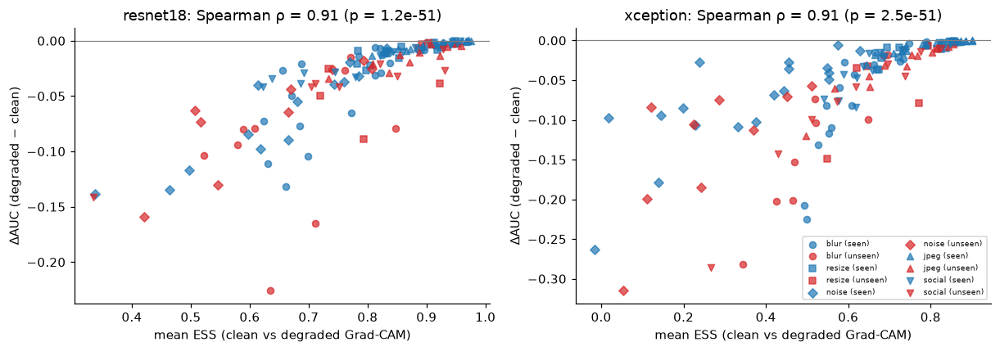

In [33]:
# 9.1  Drift ↔ performance: condition-level ESS vs ΔAUC (Trial 2), plus image-level ESS vs score change
L = T3[T3.model == "logo"]
agg = []
for g in GENS:
    sub = L[L.cls.isin([REAL, g])]
    q = sub.groupby(["arch", "heldout", "cond", "type", "severity"]).agg(ess=("ess", "mean"), dfe=("dfe", "mean")).reset_index()
    q["test_gen"] = g; agg.append(q)
T3c = pd.concat(agg).merge(T2[["arch", "heldout", "test_gen", "cond", "d_auc", "seen"]], on=["arch", "heldout", "test_gen", "cond"])
T3c.to_csv(RES_DIR / "trial3_condition_level.csv", index=False)

corr_rows = []
for a in ARCHS + ["both"]:
    for grp in ["all", "seen", "unseen"]:
        s = T3c if a == "both" else T3c[T3c.arch == a]
        s = s if grp == "all" else s[s.seen == (grp == "seen")]
        s1, s2 = s.dropna(subset=["ess", "d_auc"]), s.dropna(subset=["dfe", "d_auc"])   # constant Grad-CAM -> NaN ESS
        r1 = stats.spearmanr(s1.ess, s1.d_auc); r2 = stats.spearmanr(s2.dfe, s2.d_auc)
        corr_rows.append(dict(arch=a, subset=grp, n=len(s1), n_dropped=len(s) - len(s1), rho_ESS_vs_dAUC=r1.statistic, p_ESS=r1.pvalue,
                              rho_dFaceEnergy_vs_dAUC=r2.statistic, p_dFE=r2.pvalue))
CORR = pd.DataFrame(corr_rows); CORR.to_csv(RES_DIR / "trial3_drift_vs_performance.csv", index=False)
display(CORR.set_index(["arch", "subset"]).round(4))

img_corr = []
for a in ARCHS:
    s = L[(L.arch == a) & (L.label == 1)]
    r = stats.spearmanr(s.ess, s.dp.abs(), nan_policy="omit")
    img_corr.append(dict(arch=a, n=len(s), rho_ESS_vs_abs_dP=r.statistic, p=r.pvalue))
display(pd.DataFrame(img_corr))

markers = dict(zip(degrade.DEGRADATIONS, "osD^v"))
fig, axes = plt.subplots(1, len(ARCHS), figsize=(5.6 * len(ARCHS), 4), squeeze=False)
for ax, a in zip(axes[0], ARCHS):
    s = T3c[T3c.arch == a]
    for t, mk in markers.items():
        for seen, col in [(True, "tab:blue"), (False, "tab:red")]:
            q = s[(s.type == t) & (s.seen == seen)]
            ax.scatter(q.ess, q.d_auc, marker=mk, c=col, alpha=.7, s=28, label=f"{t} ({'seen' if seen else 'unseen'})")
    rr = CORR[(CORR.arch == a) & (CORR.subset == "all")].iloc[0]
    ax.set(xlabel="mean ESS (clean vs degraded Grad-CAM)", ylabel="ΔAUC (degraded − clean)",
           title=f"{a}: Spearman ρ = {rr.rho_ESS_vs_dAUC:.2f} (p = {rr.p_ESS:.2g})")
    ax.axhline(0, c="gray", lw=.8)
axes[0, -1].legend(fontsize=6, ncol=2); fig.tight_layout(); savefig(fig, "trial3_ess_vs_dauc"); plt.show()

median_diff       p  p_holm
arch     comparison                    type                               
resnet18 unseen-clean vs seen-clean    -            0.0039  0.0026  0.0131
         seen-degraded vs seen-clean   blur        -0.0113  0.0000  0.0000
         unseen-degraded vs seen-clean blur        -0.0091  0.0000  0.0001
         ESS unseen vs seen            blur        -0.0444  0.0000  0.0000
         seen-degraded vs seen-clean   jpeg         0.0120  0.0000  0.0000
         unseen-degraded vs seen-clean jpeg         0.0068  0.0001  0.0004
         ESS unseen vs seen            jpeg        -0.0119  0.0000  0.0000
         seen-degraded vs seen-clean   noise        0.0841  0.0000  0.0000
         unseen-degraded vs seen-clean noise        0.0446  0.0453  0.1810
         ESS unseen vs seen            noise       -0.0622  0.0000  0.0000
         seen-degraded vs seen-clean   resize      -0.0059  0.0000  0.0000
         unseen-degraded vs seen-clean resize      -0.0038  0.0000  0.0000
         ESS unseen vs seen            resize      -0.0064  0.0000  0.0000
         seen-degraded vs seen-clean   social       0.0123  0.0000  0.0000
         unseen-degraded vs seen-clean social      -0.0100  0.0000  0.0000
         ESS unseen vs seen            social      -0.0241  0.0000  0.0000
xception unseen-clean vs seen-clean    -            0.0353  0.0000  0.0000
         seen-degraded vs seen-clean   blur        -0.0267  0.0000  0.0000
         unseen-degraded vs seen-clean blur        -0.0033  0.1752  0.5257
         ESS unseen vs seen            blur        -0.0556  0.0000  0.0000
         seen-degraded vs seen-clean   jpeg         0.0140  0.0000  0.0000
         unseen-degraded vs seen-clean jpeg         0.0242  0.8898  0.8898
         ESS unseen vs seen            jpeg        -0.0384  0.0000  0.0000
         seen-degraded vs seen-clean   noise        0.0735  0.1901  0.5257
         unseen-degraded vs seen-clean noise       -0.0720  0.0000  0.0000
         ESS unseen vs seen            noise       -0.0659  0.0000  0.0000
         seen-degraded vs seen-clean   resize      -0.0059  0.0000  0.0000
         unseen-degraded vs seen-clean resize       0.0263  0.0000  0.0000
         ESS unseen vs seen            resize      -0.0172  0.0000  0.0000
         seen-degraded vs seen-clean   social       0.0186  0.0000  0.0000
         unseen-degraded vs seen-clean social      -0.0244  0.0000  0.0000
         ESS unseen vs seen            social      -0.0665  0.0000  0.0000

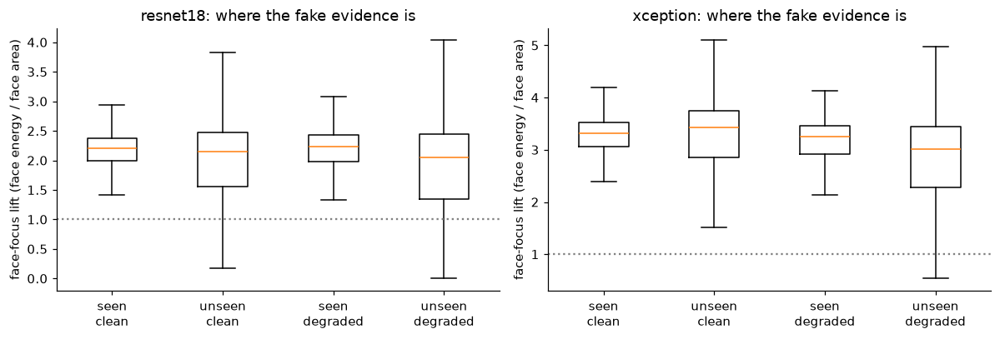

In [34]:
# 9.2  Face focus on the two roads (LOGO models, fake images; degraded = medium level of each family)
F_ = L[(L.label == 1) & L.cond.isin(MEDIUM.values())]
per = F_.groupby(["arch", "uid", "cls", "type", "status"]).agg(fe_clean=("fe_clean", "mean"), fe_deg=("fe_deg", "mean"),
                                                                ess=("ess", "mean"), area=("area", "first")).reset_index()
W = per.pivot_table(index=["arch", "uid", "cls", "type", "area"], columns="status", values=["fe_clean", "fe_deg", "ess"])
W.columns = [f"{v}_{s}" for v, s in W.columns]; W = W.reset_index().dropna()

ff_rows = []
for a in ARCHS:
    w_a = W[W.arch == a]
    base = w_a.drop_duplicates("uid")
    t = stats.wilcoxon(base.fe_clean_unseen, base.fe_clean_seen)
    ff_rows.append(dict(arch=a, comparison="unseen-clean vs seen-clean", type="-", median_diff=np.median(base.fe_clean_unseen - base.fe_clean_seen), p=t.pvalue))
    for ty, w_t in w_a.groupby("type"):
        for name, x, y in [("seen-degraded vs seen-clean", w_t.fe_deg_seen, w_t.fe_clean_seen),
                           ("unseen-degraded vs seen-clean", w_t.fe_deg_unseen, w_t.fe_clean_seen),
                           ("ESS unseen vs seen", w_t.ess_unseen, w_t.ess_seen)]:
            t = stats.wilcoxon(x, y)
            ff_rows.append(dict(arch=a, comparison=name, type=ty, median_diff=np.median(x - y), p=t.pvalue))
FF = pd.DataFrame(ff_rows); FF["p_holm"] = M.holm(FF.p); FF.to_csv(RES_DIR / "trial3_face_focus_tests.csv", index=False)
display(FF.set_index(["arch", "comparison", "type"]).round(4))

fig, axes = plt.subplots(1, len(ARCHS), figsize=(5.5 * len(ARCHS), 3.8), squeeze=False)
for ax, a in zip(axes[0], ARCHS):
    w_a = W[W.arch == a]; one = w_a.drop_duplicates("uid")
    deg = w_a.groupby("uid")[["fe_deg_seen", "fe_deg_unseen"]].mean().join(one.set_index("uid")["area"])
    data_ = [one.fe_clean_seen / one.area, one.fe_clean_unseen / one.area, deg.fe_deg_seen / deg.area, deg.fe_deg_unseen / deg.area]
    ax.boxplot(data_, showfliers=False)
    ax.set_xticks([1, 2, 3, 4], ["seen\nclean", "unseen\nclean", "seen\ndegraded", "unseen\ndegraded"])
    ax.axhline(1, ls=":", c="gray"); ax.set(ylabel="face-focus lift (face energy / face area)", title=f"{a}: where the fake evidence is")
fig.tight_layout(); savefig(fig, "trial3_face_focus_two_roads"); plt.show()

In [35]:
# 9.3  Same evidence lost?  Correlate the unseen-generator shift map with the degradation shift map on the same image
def lost_in_face(delta, masks):
    loss = np.clip(-delta, 0, None)
    tot = loss.reshape(len(loss), -1).sum(1)
    with np.errstate(invalid="ignore", divide="ignore"):
        return (loss * masks).reshape(len(loss), -1).sum(1) / tot

sh = []
for a in ARCHS:
    c_ref, _ = cams(tag_all(a))
    for g in GENS:
        idx = np.flatnonzero(CAM_CLS == g)
        ref = c_ref[idx].astype(np.float32)
        du = cams(tag_logo(a, g))[0][idx].astype(np.float32) - ref
        perm = np.random.default_rng(SEED).permutation(len(idx))
        for t, cond in MEDIUM.items():
            dd = cams(tag_all(a), cond)[0][idx].astype(np.float32) - ref
            sh.append(pd.DataFrame(dict(arch=a, gen=g, type=t, uid=CAM_DF.uid.to_numpy()[idx],
                                        r=M.rowwise_spearman(du, dd), r_null=M.rowwise_spearman(du, dd[perm]),
                                        lost_face_unseen=lost_in_face(du, MASKS[idx]), lost_face_deg=lost_in_face(dd, MASKS[idx]),
                                        area=AREA[idx])))
SH = pd.concat(sh, ignore_index=True); SH.to_csv(RES_DIR / "trial3_evidence_shift_per_image.csv.gz", index=False)

def _summ(d):
    d = d.dropna(subset=["r", "r_null"])
    t = stats.wilcoxon(d.r, d.r_null) if len(d) > 5 else None
    return pd.Series(dict(n=len(d), median_r=d.r.median(), median_r_null=d.r_null.median(), p_vs_null=t.pvalue if t else np.nan,
                          lost_in_face_unseen=d.lost_face_unseen.mean(), lost_in_face_degraded=d.lost_face_deg.mean(), face_area=d.area.mean()))
SHs = SH.groupby(["arch", "gen", "type"]).apply(_summ, include_groups=False).reset_index()
SHs["p_holm"] = M.holm(SHs.p_vs_null); SHs.to_csv(RES_DIR / "trial3_evidence_shift_summary.csv", index=False)
display(SHs.set_index(["arch", "gen", "type"]).round(4))
print("r > r_null  → the evidence a detector loses on an unseen generator is spatially the same evidence it loses under degradation.\n"
      "lost_in_face > face_area → the lost evidence sits mainly on the face; < face_area → mainly in the background.")

n  median_r  median_r_null  p_vs_null  lost_in_face_unseen  lost_in_face_degraded  face_area  p_holm
arch     gen        type                                                                                                            
resnet18 inpainting blur    297.0    0.0413        -0.0537     0.0002               0.3713                 0.3736     0.2494  0.0037
                    jpeg    298.0    0.2585         0.0405     0.0000               0.3713                 0.3212     0.2495  0.0000
                    noise   296.0    0.3959         0.1902     0.0000               0.3710                 0.3859     0.2495  0.0000
                    resize  297.0   -0.0784        -0.0949     0.8107               0.3713                 0.4209     0.2494  1.0000
                    social  296.0    0.2766         0.1058     0.0000               0.3710                 0.3644     0.2495  0.0003
         insight    blur    294.0    0.0200        -0.0375     0.0218               0.4603                 0.4343     0.2513  0.2394
                    jpeg    287.0    0.2085         0.0942     0.0000               0.4582                 0.3296     0.2513  0.0003
                    noise   288.0    0.5173         0.2556     0.0000               0.4591                 0.4166     0.2513  0.0000
                    resize  288.0   -0.0959        -0.0713     0.8218               0.4591                 0.4534     0.2513  1.0000
                    social  287.0    0.3088         0.1195     0.0000               0.4582                 0.3503     0.2513  0.0000
         text2img   blur    300.0    0.1594        -0.0096     0.0000               0.2666                 0.2905     0.2359  0.0005
                    jpeg    300.0    0.0195         0.0142     0.5933               0.2666                 0.3138     0.2359  1.0000
                    noise   300.0    0.2158         0.0682     0.0000               0.2666                 0.3736     0.2359  0.0000
                    resize  300.0    0.0509        -0.0336     0.0254               0.2666                 0.3675     0.2359  0.2520
                    social  300.0    0.0256         0.0670     0.4688               0.2666                 0.3629     0.2359  1.0000
xception inpainting blur    300.0   -0.0207        -0.1168     0.0000               0.7024                 0.6785     0.2494  0.0000
                    jpeg    300.0    0.2480         0.0679     0.0000               0.7024                 0.7118     0.2494  0.0000
                    noise   300.0    0.4650         0.2527     0.0000               0.7024                 0.7974     0.2494  0.0000
                    resize  300.0    0.0281        -0.0707     0.0061               0.7024                 0.6749     0.2494  0.0728
                    social  300.0    0.2429         0.0617     0.0000               0.7024                 0.7406     0.2494  0.0000
         insight    blur    300.0   -0.0172        -0.0753     0.0252               0.7616                 0.6667     0.2510  0.2520
                    jpeg    300.0    0.1136         0.0347     0.0012               0.7616                 0.7289     0.2510  0.0153
                    noise   300.0    0.6109         0.4285     0.0000               0.7616                 0.7970     0.2510  0.0000
                    resize  300.0    0.0054        -0.0094     0.4925               0.7616                 0.6695     0.2510  1.0000
                    social  300.0    0.1803         0.0789     0.0006               0.7616                 0.7472     0.2510  0.0088
         text2img   blur    300.0   -0.2261        -0.2270     0.3919               0.6433                 0.6974     0.2359  1.0000
                    jpeg    300.0    0.2700         0.1701     0.0000               0.6433                 0.6419     0.2359  0.0001
                    noise   300.0    0.3649         0.2461     0.0000               0.6433                 0.7794     0.2359  0.0000
                    resize  300.0   -0.211

r > r_null  → the evidence a detector loses on an unseen generator is spatially the same evidence it loses under degradation.
lost_in_face > face_area → the lost evidence sits mainly on the face; < face_area → mainly in the background.


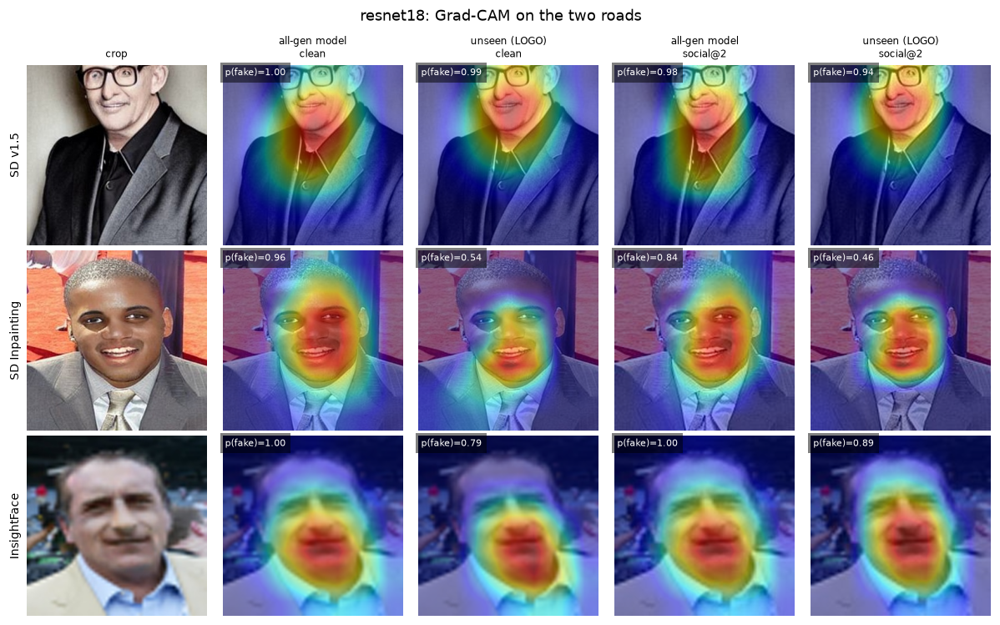

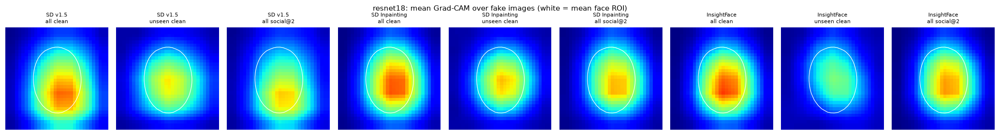

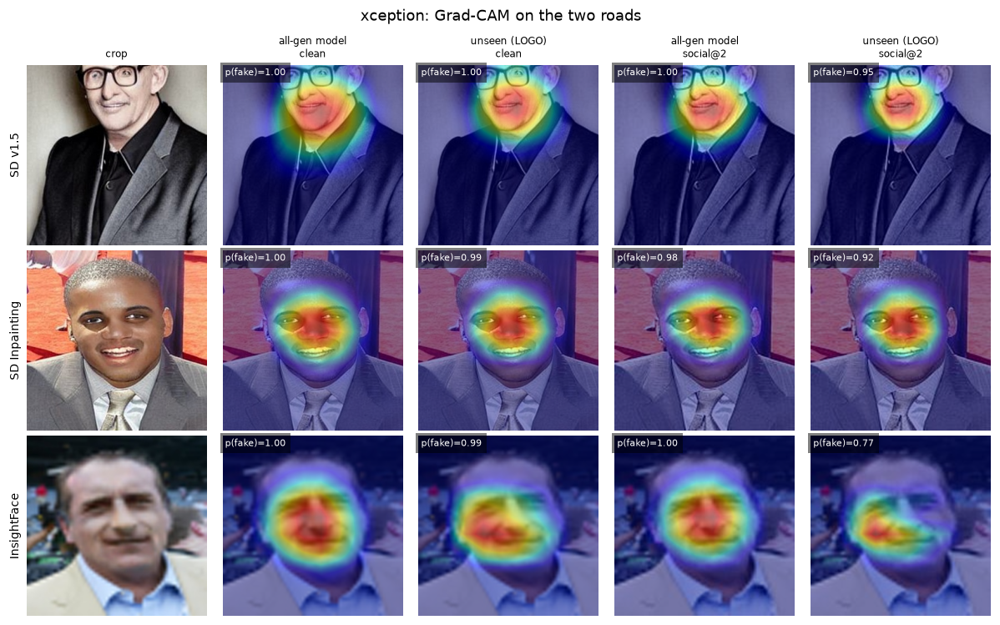

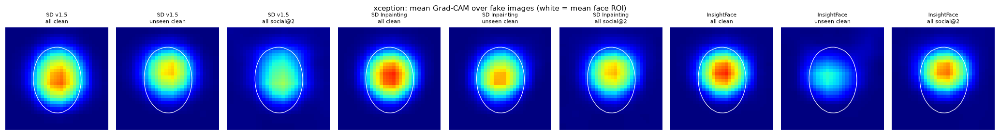

In [36]:
# 9.4  Visual: example Grad-CAMs and mean maps on the two roads
show_cond = MEDIUM["social"]
for a in ARCHS:
    c_all, p_all = cams(tag_all(a)); c_alld, p_alld = cams(tag_all(a), show_cond)
    ex_idx = [int(np.flatnonzero(CAM_CLS == g)[0]) for g in GENS]
    fig, axes = plt.subplots(len(GENS), 5, figsize=(11, 2.3 * len(GENS)))
    titles = ["crop", "all-gen model\nclean", "unseen (LOGO)\nclean", f"all-gen model\n{show_cond}", f"unseen (LOGO)\n{show_cond}"]
    for r_, (g, i) in enumerate(zip(GENS, ex_idx)):
        img = faces.read_rgb(CAM_DF.crop_path[i]); uid = CAM_DF.uid[i]
        imgd = degrade.apply_degradation(img, show_cond, uid)
        c_u, p_u = cams(tag_logo(a, g)); c_ud, p_ud = cams(tag_logo(a, g), show_cond)
        panels = [(img, None, None), (img, c_all[i], p_all[i]), (img, c_u[i], p_u[i]), (imgd, c_alld[i], p_alld[i]), (imgd, c_ud[i], p_ud[i])]
        for j, (im, cm, pr) in enumerate(panels):
            ax = axes[r_, j]; ax.imshow(im if cm is None else overlay(im, cm)); ax.axis("off")
            if r_ == 0: ax.set_title(titles[j], fontsize=8)
            if pr is not None: ax.text(4, 18, f"p(fake)={pr:.2f}", color="w", fontsize=7, bbox=dict(fc="k", alpha=.5, lw=0))
        axes[r_, 0].text(-10, CROP_SIZE / 2, GENERATORS[g], rotation=90, va="center", ha="right", fontsize=9)
    fig.suptitle(f"{a}: Grad-CAM on the two roads"); fig.tight_layout(); savefig(fig, f"trial3_examples_{a}"); plt.show()

    fig, axes = plt.subplots(1, len(GENS) * 3, figsize=(2.1 * len(GENS) * 3, 2.6))
    mean_mask = MASKS.mean(0)
    k = 0
    for g in GENS:
        idx = CAM_CLS == g
        for lab, cm in [("all clean", c_all), ("unseen clean", cams(tag_logo(a, g))[0]), (f"all {show_cond}", c_alld)]:
            axes[k].imshow(cm[idx].astype(np.float32).mean(0), cmap="jet", vmin=0, vmax=1)
            axes[k].contour(mean_mask, levels=[.5], colors="w", linewidths=.8)
            axes[k].set_title(f"{GENERATORS[g]}\n{lab}", fontsize=7); axes[k].axis("off"); k += 1
    fig.suptitle(f"{a}: mean Grad-CAM over fake images (white = mean face ROI)", fontsize=10)
    fig.tight_layout(); savefig(fig, f"trial3_mean_maps_{a}"); plt.show()

## 10 · Trial 4 — Face vs. background degradation (Objective 4, causal test)
Instead of observing where Grad-CAM points, we **intervene**: degrade only the face, only the background, or a random face-shaped region of the same area (control), and measure ΔAUC versus clean (paired bootstrap, Holm-corrected). Only images with a detected face are used.

How to read it:
- face ≫ random ≈ background → the detector's decision depends on facial evidence;
- background or random hurts as much as face → it relies on evidence that is not facial (for Inpainting/InsightFace the background is a **real** photo, so any reliance there is a shortcut);
- comparing the all-generator model (generator seen) with the LOGO model (generator unseen) tells whether the unseen-generator detector depends on a *different* region.

In [37]:
T4_TAGS = [(a, tag_logo(a, g), g) for a in ARCHS for g in GENS] + [(a, tag_all(a), "none") for a in ARCHS]
t4, fb = [], []
for a, tag, held in tqdm(T4_TAGS, desc="Trial 4"):
    p0 = preds(tag)
    for cond in T4_CONDS:
        P = {reg: preds(tag, cond, reg) for reg in T4_REGIONS}
        for g in GENS:
            m = gen_mask(g, detected_only=True); y = Y_TEST[m]
            status = "seen" if held != g else "unseen"
            for reg in T4_REGIONS:
                d = M.paired_bootstrap_delta(y, p0[m], P[reg][m], N_BOOT, SEED)
                dp = P[reg][m] - p0[m]
                t4.append(dict(arch=a, tag=tag, heldout=held, model="all" if held == "none" else "logo", test_gen=g, status=status,
                               cond=cond, region=reg, auc_clean=M.fast_auc(y, p0[m]), auc=M.fast_auc(y, P[reg][m]),
                               d_auc=d["delta"], lo=d["lo"], hi=d["hi"], p=d["p"],
                               shift_p_real=dp[y == 0].mean(), shift_p_fake=dp[y == 1].mean()))
            c = M.paired_bootstrap_delta(y, P["face"][m], P["background"][m], N_BOOT, SEED)
            fb.append(dict(arch=a, tag=tag, heldout=held, test_gen=g, status=status, cond=cond,
                           auc_bg_minus_face=c["delta"], lo=c["lo"], hi=c["hi"], p=c["p"]))
T4 = pd.DataFrame(t4); T4["p_holm"] = M.holm(T4.p); T4.to_csv(RES_DIR / "trial4_region_degradation.csv", index=False)
FB = pd.DataFrame(fb); FB["p_holm"] = M.holm(FB.p); FB.to_csv(RES_DIR / "trial4_face_vs_background.csv", index=False)

view = T4[(T4.model == "all") | (T4.status == "unseen")]
display(view.pivot_table(index=["arch", "status", "test_gen"], columns=["cond", "region"], values="d_auc").round(4))
print("AUC(background-degraded) − AUC(face-degraded); > 0 means degrading the FACE hurts more:")
display(FB[(FB.heldout == "none") | (FB.status == "unseen")].set_index(["arch", "status", "test_gen", "cond"]).round(4))

Trial 4:   0%|          | 0/8 [00:00<?, ?it/s]

cond                           blur@2                             jpeg@3                        
region                     background    face    full  random background    face    full  random
arch     status test_gen                                                                        
resnet18 seen   inpainting    -0.0064 -0.0252 -0.0432 -0.0033    -0.0018 -0.0016 -0.0050 -0.0007
                insight       -0.0123 -0.0483 -0.0862 -0.0077    -0.0005 -0.0023 -0.0034 -0.0008
                text2img      -0.0008 -0.0105 -0.0135 -0.0013    -0.0013 -0.0006 -0.0033 -0.0003
         unseen inpainting    -0.0151 -0.1478 -0.0744 -0.0189    -0.0062 -0.0021 -0.0097 -0.0012
                insight       -0.0554 -0.0346 -0.1633 -0.0203    -0.0110 -0.0054 -0.0198 -0.0030
                text2img      -0.0008 -0.0857 -0.0706 -0.0198    -0.0035 -0.0033 -0.0115 -0.0007
xception seen   inpainting    -0.0072 -0.0464 -0.0428 -0.0120    -0.0028 -0.0031 -0.0160 -0.0010
                insight       -0.0300 -0.0991 -0.1036 -0.0237    -0.0015 -0.0025 -0.0082 -0.0006
                text2img      -0.0026 -0.0342 -0.0239 -0.0094    -0.0020 -0.0032 -0.0209 -0.0008
         unseen inpainting    -0.0155 -0.0918 -0.0698 -0.0257    -0.0060 -0.0061 -0.0175 -0.0026
                insight       -0.0575 -0.0475 -0.2014 -0.0227    -0.0244 -0.0119 -0.0448 -0.0079
                text2img      -0.0195 -0.0755 -0.0947 -0.0391    -0.0110 -0.0188 -0.0573 -0.0066

AUC(background-degraded) − AUC(face-degraded); > 0 means degrading the FACE hurts more:


tag     heldout  auc_bg_minus_face      lo      hi       p  p_holm
arch     status test_gen   cond                                                                                            
resnet18 unseen text2img   blur@2    resnet18__logo-text2img    text2img             0.0849  0.0787  0.0916  0.0000  0.0000
                           jpeg@3    resnet18__logo-text2img    text2img            -0.0003 -0.0013  0.0008  0.6560  1.0000
                inpainting blur@2  resnet18__logo-inpainting  inpainting             0.1327  0.1249  0.1411  0.0000  0.0000
                           jpeg@3  resnet18__logo-inpainting  inpainting            -0.0041 -0.0052 -0.0028  0.0000  0.0000
                insight    blur@2     resnet18__logo-insight     insight            -0.0208 -0.0250 -0.0166  0.0000  0.0000
                           jpeg@3     resnet18__logo-insight     insight            -0.0055 -0.0074 -0.0038  0.0000  0.0000
xception unseen text2img   blur@2    xception__logo-text2img    text2img             0.0560  0.0502  0.0618  0.0000  0.0000
                           jpeg@3    xception__logo-text2img    text2img             0.0078  0.0060  0.0095  0.0000  0.0000
                inpainting blur@2  xception__logo-inpainting  inpainting             0.0762  0.0706  0.0819  0.0000  0.0000
                           jpeg@3  xception__logo-inpainting  inpainting             0.0001 -0.0009  0.0011  0.8844  1.0000
                insight    blur@2     xception__logo-insight     insight            -0.0100 -0.0156 -0.0046  0.0003  0.0054
                           jpeg@3     xception__logo-insight     insight            -0.0125 -0.0152 -0.0102  0.0000  0.0000
resnet18 seen   text2img   blur@2              resnet18__all        none             0.0097  0.0082  0.0113  0.0000  0.0000
                inpainting blur@2              resnet18__all        none             0.0188  0.0160  0.0215  0.0000  0.0000
                insight    blur@2              resnet18__all        none             0.0360  0.0322  0.0399  0.0000  0.0000
                text2img   jpeg@3              resnet18__all        none            -0.0007 -0.0010 -0.0004  0.0000  0.0001
                inpainting jpeg@3              resnet18__all        none            -0.0003 -0.0007  0.0002  0.2183  1.0000
                insight    jpeg@3              resnet18__all        none             0.0018  0.0012  0.0023  0.0000  0.0000
xception seen   text2img   blur@2              xception__all        none             0.0316  0.0286  0.0348  0.0000  0.0000
                inpainting blur@2              xception__all        none             0.0392  0.0357  0.0428  0.0000  0.0000
                insight    blur@2              xception__all        none             0.0691  0.0638  0.0746  0.0000  0.0000
                text2img   jpeg@3              xception__all        none             0.0012  0.0006  0.0018  0.0001  0.0011
                inpainting jpeg@3              xception__all        none             0.0003 -0.0003  0.0009  0.3077  1.0000
                insight    jpeg@3              xception__all        none             0.0010  0.0004  0.0017  0.0016  0.0203

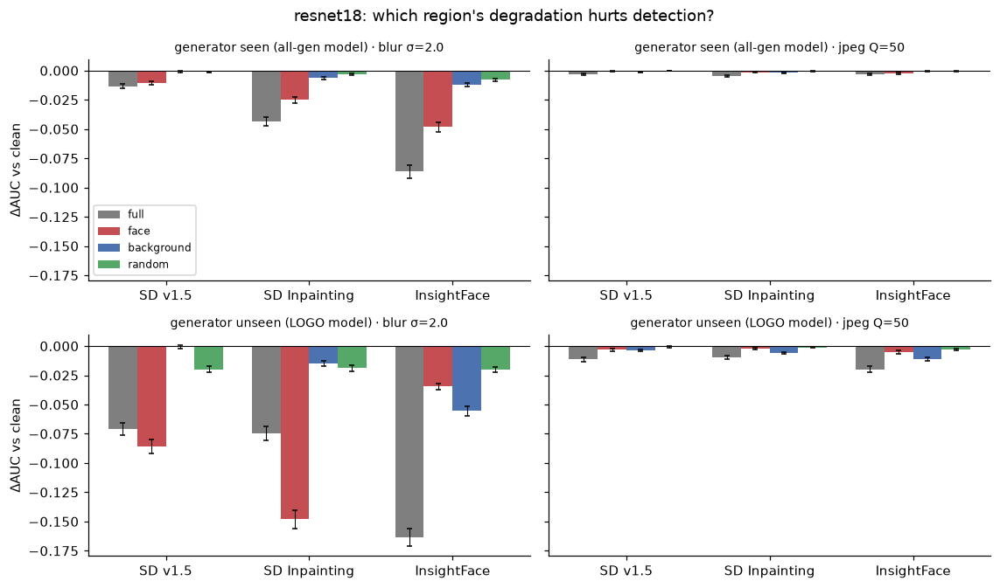

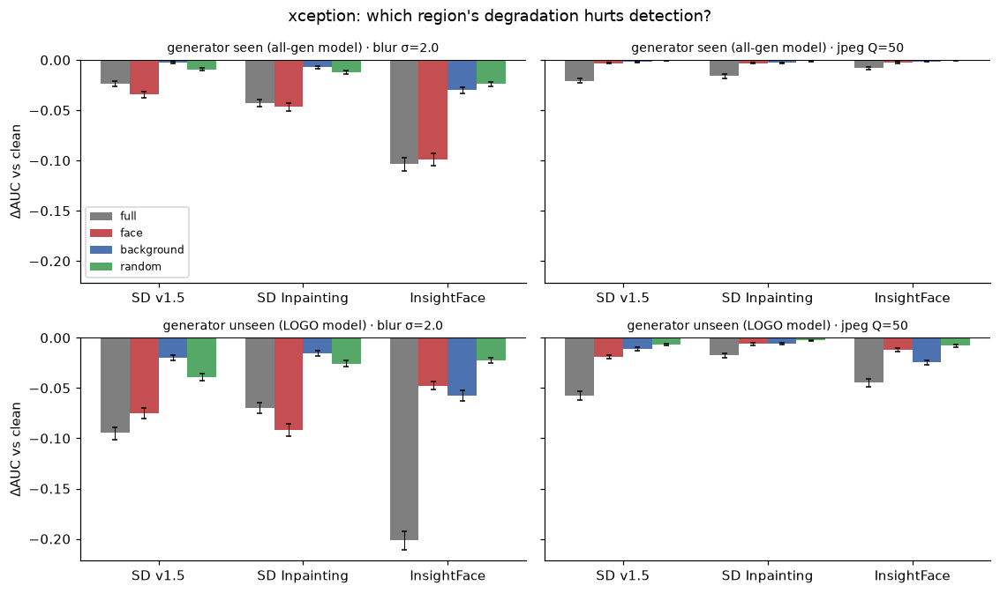

In [38]:
cols = {"full": "#7f7f7f", "face": "#C44E52", "background": "#4C72B0", "random": "#55A868"}
for a in ARCHS:
    fig, axes = plt.subplots(2, len(T4_CONDS), figsize=(5.2 * len(T4_CONDS), 6.2), sharey=True, squeeze=False)
    for i, (lab, sel_) in enumerate([("generator seen (all-gen model)", lambda d: d.model == "all"),
                                     ("generator unseen (LOGO model)", lambda d: d.status == "unseen")]):
        for j, cond in enumerate(T4_CONDS):
            ax = axes[i, j]; d = T4[(T4.arch == a) & (T4.cond == cond)]; d = d[sel_(d)]
            x = np.arange(len(GENS)); wdt = .2
            for k, reg in enumerate(T4_REGIONS):
                q = d[d.region == reg].set_index("test_gen").reindex(GENS)
                ax.bar(x + (k - 1.5) * wdt, q.d_auc, wdt, color=cols[reg], label=reg,
                       yerr=[q.d_auc - q.lo, q.hi - q.d_auc], capsize=2, error_kw=dict(lw=.7))
            ax.axhline(0, c="k", lw=.7); ax.set_xticks(x, [GENERATORS[g] for g in GENS])
            ax.set_title(f"{lab} · {COND[cond]['label']}", fontsize=9)
            if j == 0: ax.set_ylabel("ΔAUC vs clean")
    axes[0, 0].legend(fontsize=8); fig.suptitle(f"{a}: which region's degradation hurts detection?"); fig.tight_layout()
    savefig(fig, f"trial4_regions_{a}"); plt.show()

## 11 · Statistical analysis summary
All hypothesis tests in one table, Holm-corrected within each family. Paired bootstrap tests compare AUCs on the **same** test images; Wilcoxon signed-rank tests compare per-image explanation measures; Spearman ρ relates explanation drift to performance loss.

In [39]:
fam = []
fam.append(TU.assign(family="T2 unseen vs seen generator (ΔAUC)", test="paired DeLong",
                     what=TU.arch + " " + TU.test_gen + " vs " + TU.seen_model, effect=TU.delta)[["family", "test", "what", "effect", "p"]])
fam.append(TD.assign(family="T2 clean → degraded (ΔAUC)", test="paired DeLong",
                     what=TD.arch + " logo-" + TD.heldout + " on " + TD.test_gen + " " + TD.cond, effect=TD.delta)[["family", "test", "what", "effect", "p"]])
if len(TWO) > 5:
    fam.append(pd.DataFrame([dict(family="T2 both-at-once interaction", test="Wilcoxon (median = 0)", what="all arch × gen × family",
                                  effect=TWO.interaction.mean(), p=stats.wilcoxon(TWO.interaction).pvalue)]))
fam.append(CORR.assign(family="T3 ESS vs ΔAUC", test="Spearman", what=CORR.arch + " / " + CORR.subset,
                       effect=CORR.rho_ESS_vs_dAUC, p=CORR.p_ESS)[["family", "test", "what", "effect", "p"]])
fam.append(FF.assign(family="T3 face focus / ESS on two roads", test="Wilcoxon signed-rank",
                     what=FF.arch + " " + FF.comparison + " " + FF.type, effect=FF.median_diff)[["family", "test", "what", "effect", "p"]])
fam.append(SHs.assign(family="T3 same evidence lost (r vs shuffled)", test="Wilcoxon signed-rank",
                      what=SHs.arch + " " + SHs.gen + " " + SHs.type, effect=SHs.median_r - SHs.median_r_null, p=SHs.p_vs_null)[["family", "test", "what", "effect", "p"]])
fam.append(T4.assign(family="T4 region degradation (ΔAUC)", test="paired DeLong",
                     what=T4.tag + " on " + T4.test_gen + " " + T4.cond + " " + T4.region, effect=T4.d_auc)[["family", "test", "what", "effect", "p"]])
fam.append(FB.assign(family="T4 face vs background", test="paired DeLong",
                     what=FB.tag + " on " + FB.test_gen + " " + FB.cond, effect=FB.auc_bg_minus_face)[["family", "test", "what", "effect", "p"]])
STATS = pd.concat(fam, ignore_index=True)
STATS["p_holm"] = STATS.groupby("family").p.transform(lambda p: M.holm(p.to_numpy()))
STATS["significant"] = STATS.p_holm < 0.05
STATS.to_csv(RES_DIR / "statistics_all_tests.csv", index=False)
display(STATS.groupby("family").agg(tests=("p", "size"), significant=("significant", "sum"), mean_effect=("effect", "mean")).round(4))

,tests,significant,mean_effect
family,,,
T2 both-at-once interaction,1,1,0.0383
T2 clean → degraded (ΔAUC),270,266,-0.0432
T2 unseen vs seen generator (ΔAUC),12,12,-0.0401
T3 ESS vs ΔAUC,9,9,0.8911
T3 face focus / ESS on two roads,32,28,-0.0065
T3 same evidence lost (r vs shuffled),30,18,0.1025
T4 face vs background,48,36,0.0199
T4 region degradation (ΔAUC),192,188,-0.0209


## 12 · Findings — answering "two roads or one?"
The cell below prints the headline numbers that decide the research question:

| Evidence | "Same road" if … | "Different roads" if … |
|---|---|---|
| T3 evidence-shift correlation | median r clearly above the shuffled baseline | r ≈ r_null |
| T3 face focus | both unseen and degraded conditions move face energy in the same direction | they move in opposite directions |
| T3 lost-in-face share | both roads lose evidence in the same region (face vs. background) | one loses face evidence, the other background evidence |
| T4 causal test | the region whose degradation hurts most is the same for the seen and the unseen model | it differs |

In [40]:
for a in ARCHS:
    print(f"\n=================== {a} ===================")
    t1 = T1[(T1.arch == a) & (T1.train_set == "all")]
    print(f"Trial 1  all-generator model, clean AUC: " + ", ".join(f"{g} {v:.3f}" for g, v in zip(t1.test_gen, t1.auc)))
    tw = TWO[TWO.arch == a]
    print(f"Trial 2  mean AUC drop – unseen generator {tw.drop_unseen.mean():.3f} | degradation (medium) {tw.drop_deg.mean():.3f} | "
          f"both {tw.drop_both.mean():.3f} | interaction {tw.interaction.mean():+.3f}")
    worst = tw.groupby("type").drop_deg.mean().sort_values(ascending=False)
    print(f"         most damaging degradation family: {worst.index[0]} ({worst.iloc[0]:.3f})")
    cr = CORR[(CORR.arch == a) & (CORR.subset == "all")].iloc[0]
    verdict = ("could not be computed" if pd.isna(cr.rho_ESS_vs_dAUC) else
               f"more explanation drift {'goes with' if cr.rho_ESS_vs_dAUC > 0 and cr.p_ESS < .05 else 'does not clearly go with'} "
               "more performance loss")
    print(f"Trial 3  ESS vs ΔAUC: ρ = {cr.rho_ESS_vs_dAUC:.2f} (p = {cr.p_ESS:.2g}, n = {cr.n})  → {verdict}")
    s = SHs[SHs.arch == a]
    print(f"         evidence-shift correlation: median r = {s.median_r.mean():.3f} vs shuffled {s.median_r_null.mean():.3f}; "
          f"significant in {(s.p_holm < .05).sum()}/{len(s)} generator×degradation cells")
    print(f"         share of lost evidence inside face – unseen road {s.lost_in_face_unseen.mean():.2f}, degradation road "
          f"{s.lost_in_face_degraded.mean():.2f} (face area {s.face_area.mean():.2f})")
    for status, sel_ in [("seen (all-gen)", (T4.arch == a) & (T4.model == "all")), ("unseen (LOGO)", (T4.arch == a) & (T4.status == "unseen"))]:
        r = T4[sel_ & (T4.region != "full")].groupby("region").d_auc.mean()
        print(f"Trial 4  {status:15s} mean ΔAUC by region: " + ", ".join(f"{k} {v:+.3f}" for k, v in r.items())
              + f"  → most damaging region: {r.idxmin()}")


=================== resnet18 ===================
Trial 1  all-generator model, clean AUC: text2img 0.997, inpainting 0.992, insight 0.987
Trial 2  mean AUC drop – unseen generator 0.043 | degradation (medium) 0.020 | both 0.089 | interaction +0.025
         most damaging degradation family: blur (0.049)
Trial 3  ESS vs ΔAUC: ρ = 0.91 (p = 1.2e-51, n = 135)  → more explanation drift goes with more performance loss
         evidence-shift correlation: median r = 0.155 vs shuffled 0.044; significant in 9/15 generator×degradation cells
         share of lost evidence inside face – unseen road 0.37, degradation road 0.37 (face area 0.25)
Trial 4  seen (all-gen)  mean ΔAUC by region: background -0.004, face -0.015, random -0.002  → most damaging region: face
Trial 4  unseen (LOGO)   mean ΔAUC by region: background -0.015, face -0.046, random -0.011  → most damaging region: face

=================== xception ===================
Trial 1  all-generator model, clean AUC: text2img 0.999, inpaint

## 13 · (Optional) Does one fix help both roads?
The proposal's practical hypothesis: if both failures share a cause, **training with degraded images** may help on unseen generators too. With `RUN_REMEDY = True`, each LOGO model is retrained with a random degradation applied to `REMEDY_AUG_P` of training images, and compared with the plain LOGO model on the unseen generator (clean and degraded) and on seen generators.

In [41]:
if RUN_REMEDY:
    rem = []
    for a in ARCHS:
        for g in GENS:
            base, aug = tag_logo(a, g), tag_logo(a, g) + "__degaug"
            train(aug, a, [h for h in GENS if h != g], aug_degrade_p=REMEDY_AUG_P)
            for tg, kind in [(base, "plain"), (aug, "degraded-aug")]:
                for cond in ["clean"] + list(MEDIUM.values()):
                    for h in GENS:
                        rem.append(dict(arch=a, heldout=g, training=kind, test_gen=h, status="unseen" if h == g else "seen",
                                        cond=cond, auc=evaluate(tg, h, cond)["auc"]))
    REM = pd.DataFrame(rem); REM.to_csv(RES_DIR / "remedy_degradation_training.csv", index=False)
    REM["condition"] = np.where(REM.cond == "clean", "clean", "degraded")
    display(REM.pivot_table(index=["arch", "status", "condition"], columns="training", values="auc", aggfunc="mean").round(4))
else:
    print("Skipped (set RUN_REMEDY = True in §1 to run).")

Skipped (set RUN_REMEDY = True in §1 to run).


## 14 · Demo
`demo(path)` runs the full pipeline on any image: MTCNN face crop → P(fake) → Grad-CAM on the clean image and on a degraded copy, with ESS and face energy. Used for the presentation demo (Nov 20).

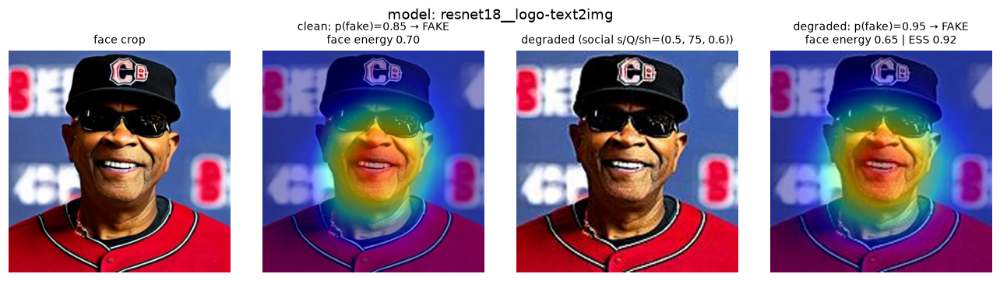

{'p_clean': 0.8492745161056519,
 'p_degraded': 0.952601432800293,
 'ess': 0.9186286751574662,
 'face_energy': [0.7049238856587791, 0.6496978746547896]}

In [42]:
_DEMO_MTCNN = None
def demo(image_path, tag=None, cond="social@2"):
    global _DEMO_MTCNN
    tag = tag or tag_all(ARCHS[0])
    if _DEMO_MTCNN is None:
        from facenet_pytorch import MTCNN
        _DEMO_MTCNN = MTCNN(keep_all=True, device=MTCNN_DEVICE, post_process=False)
    img = faces.read_rgb(image_path); H, W = img.shape[:2]
    canvas, scale, px, py = faces.letterbox(img, DETECT_SIZE)
    face = faces.pick_face(*faces.mtcnn_detect(_DEMO_MTCNN, canvas[None])[0], MIN_FACE_PROB)
    box = lm = None
    if face is not None:
        box = (face[0] - np.array([px, py, px, py])) / scale; lm = (face[1] - np.array([px, py])) / scale
    cx0, cy0, cside = faces.square_crop_params(box, W, H, CROP_MARGIN)
    crop = faces.make_crop(img, cx0, cy0, cside, None, CROP_SIZE, EQUALIZE_JPEG_Q)
    geo = dict(detected=face is not None, **faces.crop_geometry(box, lm, cx0, cy0, cside))
    fmask = cv2.resize(faces.face_mask(geo, CROP_SIZE, CROP_MARGIN), (CAM_RES, CAM_RES), interpolation=cv2.INTER_AREA)

    model, ck = get_model(tag); s = ck["spec"]
    degraded = degrade.apply_degradation(crop, cond, "demo")
    def prep(im):
        im = cv2.resize(im, (s["input_size"],) * 2, interpolation=cv2.INTER_AREA)
        x = (im.astype(np.float32) / 255 - np.array(s["mean"], np.float32)) / np.array(s["std"], np.float32)
        return torch.from_numpy(x.transpose(2, 0, 1).copy())
    cm, pf = C.gradcam_batch(model, torch.stack([prep(crop), prep(degraded)]).to(DEVICE), CAM_RES)
    ess = M.rowwise_spearman(cm[:1], cm[1:])[0]; fe = M.face_energy(cm, np.stack([fmask, fmask]))
    thr = ck["threshold"]
    fig, axes = plt.subplots(1, 4, figsize=(12, 3.3))
    for ax, im, t in zip(axes, [crop, overlay(crop, cm[0]), degraded, overlay(degraded, cm[1])],
                         ["face crop" + ("" if face is not None else " (no face found)"),
                          f"clean: p(fake)={pf[0]:.2f} → {'FAKE' if pf[0] >= thr else 'REAL'}\nface energy {fe[0]:.2f}",
                          f"degraded ({COND[cond]['label']})",
                          f"degraded: p(fake)={pf[1]:.2f} → {'FAKE' if pf[1] >= thr else 'REAL'}\nface energy {fe[1]:.2f} | ESS {ess:.2f}"]):
        ax.imshow(im); ax.set_title(t, fontsize=9); ax.axis("off")
    fig.suptitle(f"model: {tag}"); fig.tight_layout(); plt.show()
    return dict(p_clean=float(pf[0]), p_degraded=float(pf[1]), ess=float(ess), face_energy=fe.tolist())

# Example: one unseen-generator fake from the test set
ex = TEST[(TEST.cls == GENS[0]) & (TEST.detected == 1)].iloc[0]
demo(ex.path, tag=tag_logo(ARCHS[0], GENS[0]))

## 15 · Export
Collects every results table and figure into `work/results_bundle.zip` for the report.

In [43]:
import zipfile
bundle = WORK / "results_bundle.zip"
with zipfile.ZipFile(bundle, "w", zipfile.ZIP_DEFLATED) as z:
    for f in sorted(list(RES_DIR.glob("*")) + list(FIG_DIR.glob("*.png"))):
        z.write(f, f"{f.parent.name}/{f.name}")
    z.write(WORK / "meta.csv", "data/meta.csv")
print(f"Results tables: {len(list(RES_DIR.glob('*')))} | figures: {len(list(FIG_DIR.glob('*.png')))}")
print(f"Bundle: {bundle}  ({bundle.stat().st_size / 1e6:.1f} MB)")
for f in sorted(RES_DIR.glob("*")): print("  ", f.name)

Results tables: 14 | figures: 17
Bundle: /tmp/ozj079/CMPT819Project/work/results_bundle.zip  (58.5 MB)
   statistics_all_tests.csv
   trial1_baseline.csv
   trial2_clean_seen_vs_unseen.csv
   trial2_degradation_tests.csv
   trial2_grid.csv
   trial2_two_roads_2x2.csv
   trial3_condition_level.csv
   trial3_drift_vs_performance.csv
   trial3_evidence_shift_per_image.csv.gz
   trial3_evidence_shift_summary.csv
   trial3_face_focus_tests.csv
   trial3_per_image.csv.gz
   trial4_face_vs_background.csv
   trial4_region_degradation.csv


In [ ]:
z